# Лабораторная работа №3
# Выполнил студент группы МОАм-251 Козырев А.Д.

Строю промышленный ELT-пайплайн для рекомендательной системы из ЛР-1: события кликстрима каждый час проходят извлечение, проверку качества, загрузку в Delta Lake через MERGE, трансформацию в dbt и публикацию рекомендаций. Цель: показать идемпотентность, обработку ошибок с DLQ и schema drift, оркестрацию в Prefect, проверки Great Expectations, dbt-модели и CI/CD с безопасным деплоем.

In [ ]:
import importlib.util, subprocess, sys, os
_need = {'prefect': 'prefect>=3', 'dbt': 'dbt-duckdb', 'deltalake': 'deltalake', 'great_expectations': 'great_expectations',
         'networkx': 'networkx', 'pytest': 'pytest', 'kagglehub': 'kagglehub', 'psutil': 'psutil', 'nbformat': 'nbformat'}
_missing = [pkg for mod, pkg in _need.items() if importlib.util.find_spec(mod) is None]
try:
    import importlib.metadata as _md
    if tuple(int(x) for x in _md.version('duckdb').split('.')[:2]) < (1, 3):
        _missing.append('duckdb>=1.3')
    _md.version('dbt-duckdb')
except _md.PackageNotFoundError:
    _missing.append('dbt-duckdb')
if _missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *sorted(set(_missing))], check=True)

# настройки окружения до импорта Prefect и GX
os.makedirs('work', exist_ok=True)
os.environ['PREFECT_HOME'] = os.path.abspath('work/.prefect')
os.environ['PREFECT_LOGGING_TO_API_ENABLED'] = 'false'
os.environ['PREFECT_LOGGING_LEVEL'] = 'CRITICAL'   # ожидаемые сбои в проверках не выводят трассировки
os.environ['PREFECT_SERVER_ANALYTICS_ENABLED'] = 'false'
os.environ['GX_ANALYTICS_ENABLED'] = 'False'
os.environ['DO_NOT_TRACK'] = '1'
os.environ['DBT_SEND_ANONYMOUS_USAGE_STATS'] = 'false'
os.environ['LAB3_ROOT'] = os.path.abspath('work')
os.environ['LAB3_GX_ROOT'] = os.path.abspath('.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import glob, json, shutil, time, base64, inspect, logging, warnings, urllib.request
warnings.filterwarnings('ignore')
from datetime import date, datetime, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import duckdb
import pyarrow as pa
import deltalake
import networkx as nx
import great_expectations as gx
import prefect
from IPython.display import display, HTML, Image, Markdown

warnings.filterwarnings('ignore')
logging.getLogger('great_expectations').setLevel(logging.ERROR)

SEED = 42
np.random.seed(SEED)
N_CORES = os.cpu_count()
RAM_GB = psutil.virtual_memory().total / 2**30

CSV = '2019-Oct.csv'
LANDING = 'work/landing'
START = date(2019, 10, 1)
# 10 дней истории: на таком окне в ЛР-1 был лучший HitRate@10; при RAM < 8 ГБ окно сокращается до 2 дней
HISTORY_DAYS = 10 if RAM_GB >= 8 else 2
HISTORY = [(START + timedelta(d)).isoformat() for d in range(HISTORY_DAYS)]
HOURLY_DAY = (START + timedelta(HISTORY_DAYS)).isoformat()      # день ежечасных запусков
LANDING_DAYS = HISTORY_DAYS + 2                                 # +1 день на ежечасные запуски, +1 на оценку рекомендаций
HOURLY_RUNS = 6

# Тарифы Yandex Compute Cloud (регион Россия, с НДС), как в ЛР-1 и ЛР-2
PRICE = {'vm_vcpu_hour': 1.24, 'vm_ram_gb_hour': 0.33}

COLORS = {'etl': '#2a78d6', 'elt': '#1baf7a', 'ok': '#1baf7a', 'fail': '#e34948', 'warn': '#eda100', 'grey': '#8a8984'}
plt.rcParams.update({
    'figure.figsize': (10, 4.2), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ad',
    'axes.grid': True, 'grid.color': '#e6e5df', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'lines.linewidth': 2, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'legend.frameon': False,
})
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

import dbt.version
display(pd.DataFrame([
    ('CPU, логических ядер', N_CORES), ('RAM, ГБ', round(RAM_GB, 1)), ('Python', sys.version.split()[0]),
    ('Prefect', prefect.__version__), ('dbt-core', dbt.version.__version__), ('DuckDB', duckdb.__version__),
    ('deltalake', deltalake.__version__), ('Great Expectations', gx.__version__), ('pandas', pd.__version__),
    ('Дней истории', HISTORY_DAYS),
], columns=['Компонент', 'Значение']))

,Компонент,Значение
0,"CPU, логических ядер",2
1,"RAM, ГБ",12.7
2,Python,3.13.18
3,Prefect,3.9.2
4,dbt-core,1.12.6
5,DuckDB,1.3.2
6,deltalake,1.6.6
7,Great Expectations,1.24.1
8,pandas,2.2.3
9,Дней истории,10


## Вариант, данные и бизнес-сценарий

Вариант 5: **E-commerce Clickstream**, файл `2019-Oct.csv` из набора *eCommerce behavior data from multi category store* (Kaggle, mkechinov). Это все события мультикатегорийного магазина за октябрь 2019 года (просмотры, корзины, покупки): 42,4 млн строк, 5,3 ГБ.

Бизнес-сценарий: **2. Рекомендательная система** (продолжение ЛР-1). Цель: ежечасное обновление рекомендаций для пользователей. Требования: задержка обработки < 45 минут, данные согласованы с production-моделью, при ошибке остаются предыдущие рекомендации. Модель взята из ЛР-1: «популярное в категории интереса пользователя» по покупкам за последние 10 дней, 10 товаров в списке.

In [ ]:
import kagglehub, os

p = kagglehub.dataset_download(
    'mkechinov/ecommerce-behavior-data-from-multi-category-store',
    path='2019-Oct.csv'
)
if os.path.isdir(p):
    p = os.path.join(p, '2019-Oct.csv')
print(p, os.path.exists(p))

if not os.path.lexists('2019-Oct.csv'):
    os.symlink(p, '2019-Oct.csv')

100%|██████████| 1.61G/1.61G [01:22<00:00, 21.1MB/s]

Extracting zip of 2019-Oct.csv...


/root/.cache/kagglehub/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/versions/8/2019-Oct.csv True


In [ ]:
if not os.path.exists(CSV):
    import kagglehub
    kagglehub.dataset_download('mkechinov/ecommerce-behavior-data-from-multi-category-store',
                               path='2019-Oct.csv', output_dir='.')
    shutil.rmtree('.complete', ignore_errors=True)
print(f'{CSV}: {os.path.getsize(CSV):,} байт'.replace(',', ' '))

2019-Oct.csv: 5 668 612 855 байт


Источник пайплайна - landing-зона: события, разложенные по часовым файлам Parquet `landing/dt=YYYY-MM-DD/hr=HH/`. Так выглядит выгрузка из Kafka раз в час. Все поля сохраняются строками, как пришли от источника: приведение типов и проверки делает сам пайплайн. В landing попадают первые `LANDING_DAYS` дней октября: история, день ежечасных запусков и следующий день, на котором проверяется качество рекомендаций.

In [ ]:
LANDING_END = (START + timedelta(LANDING_DAYS)).isoformat()
LANDING_DATES = [(START + timedelta(d)).isoformat() for d in range(LANDING_DAYS)]
todo = [d for d in LANDING_DATES if not os.path.exists(f'{LANDING}/dt={d}/_SUCCESS')]
if todo:
    os.makedirs('work/duck_tmp', exist_ok=True)
    os.makedirs(LANDING, exist_ok=True)
    con = duckdb.connect()
    con.execute(f"SET memory_limit='{int(RAM_GB * 0.25 * 1024)}MB'; SET preserve_insertion_order=false; "
                f"SET temp_directory='work/duck_tmp'; SET threads={min(4, N_CORES)}")
    window = 'work/landing_window.parquet'
    # один проход по CSV: нужные дни в общий Parquet, все поля строками
    con.execute(f"""COPY (SELECT * FROM read_csv('{CSV}', header=true, all_varchar=true)
                          WHERE event_time >= '{todo[0]}' AND event_time < '{LANDING_END}')
                    TO '{window}' (FORMAT parquet, COMPRESSION zstd)""")
    for d in todo:
        nxt = (date.fromisoformat(d) + timedelta(1)).isoformat()
        con.execute(f"""COPY (SELECT *, substr(event_time, 12, 2) AS hr FROM read_parquet('{window}')
                              WHERE event_time >= '{d}' AND event_time < '{nxt}')
                        TO '{LANDING}/dt={d}' (FORMAT parquet, COMPRESSION zstd, PARTITION_BY (hr), OVERWRITE_OR_IGNORE)""")
        open(f'{LANDING}/dt={d}/_SUCCESS', 'w').close()
    con.close()
    os.remove(window)

con = duckdb.connect()
daily = con.execute(f"""
    SELECT substr(event_time, 1, 10) AS day, count(*) AS events,
           count(*) FILTER (WHERE TRY_CAST(price AS DOUBLE) <= 0) AS price_le0,
           count(*) FILTER (WHERE user_session IS NULL) AS no_session,
           count(*) FILTER (WHERE event_type = 'purchase') AS purchases,
           count(DISTINCT user_id) AS users
    FROM read_parquet('{LANDING}/dt=*/hr=*/*.parquet', hive_partitioning=false)
    WHERE event_time < '{LANDING_END}'
    GROUP BY 1 ORDER BY 1""").df()
con.close()
daily['bad_share_%'] = ((daily.price_le0 + daily.no_session) / daily.events * 100).round(3)
n_files = len(glob.glob(f'{LANDING}/dt=*/hr=*/*.parquet'))
print(f'Часовых файлов в landing: {n_files}, размер {sum(os.path.getsize(f) for f in glob.glob(f"{LANDING}/dt=*/hr=*/*.parquet")) / 2**20:.0f} МБ')
display(daily)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Часовых файлов в landing: 288, размер 294 МБ


,day,events,price_le0,no_session,purchases,users,bad_share_%
0,2019-10-01,1244245,2129,0,19307,190188,0.171
1,2019-10-02,1191328,1821,0,19469,184965,0.153
2,2019-10-03,1127303,1353,0,19255,170668,0.120
3,2019-10-04,1417190,1519,0,27041,209410,0.107
4,2019-10-05,1330339,1292,0,23494,194958,0.097
5,2019-10-06,1318379,1070,1,22171,193210,0.081
6,2019-10-07,1200531,1836,0,21378,186951,0.153
7,2019-10-08,1370633,5597,0,23072,221204,0.408
8,2019-10-09,1347543,4987,0,22748,214140,0.370
9,2019-10-10,1284077,2740,0,21993,205321,0.213


## Часть 1: Проектирование пайплайна

### 1) Определите, использовать ETL или ELT для вашего сценария:

**Обоснуйте выбор (объем данных, тип трансформаций, инфраструктура)**

- **Объём:** около 1,4 млн событий в сутки (174 МБ CSV, 22 МБ Parquet, ЛР-1), за год 7,8 ГБ в Parquet. Это меньше порога «> 1 ТБ» из лекции, то есть объём сам по себе ELT не требует.
- **Тип трансформаций:** очистка, дедупликация, агрегации по пользователям и товарам, ранжирование популярности. Всё выражается SQL, сложной обработки (NLP, декодирования медиа) нет. Это профиль ELT.
- **Инфраструктура:** один сервер без отдельного кластера трансформаций. Хранилищем служит Delta Lake (Parquet + журнал транзакций), SQL-движком DuckDB, который работает в процессе пайплайна и читает Delta напрямую.
- **Задержка:** часовые окна (near-real-time), сырые данные должны оставаться доступными для пересчёта, если модель или логика витрин поменяется.

Выбран **ELT с лёгкой проверкой на входе**: сырые события после технической валидации (типы, обязательные поля, DLQ) грузятся в Delta как есть (bronze), а все бизнес-трансформации идут SQL-моделями dbt внутри DuckDB. Технические проверки до загрузки нужны, чтобы битые строки не попадали в хранилище; это не трансформация в смысле ETL.

**Сравните затраты для обоих подходов.** Одна и та же трансформация (очистка, топ-10 товаров в категории, профиль пользователя) выполнена двумя способами на одном и на всех днях истории:
- ETL: данные читаются в pandas, трансформируются в Python, в хранилище пишется только результат;
- ELT: сырые строки загружаются в DuckDB, трансформация выполняется SQL внутри него.

Каждый запуск идёт отдельным процессом, замеряются время, пиковая память (RSS) и процессорное время. Если процесс выходит за бюджет памяти (50% доступной RAM), он останавливается и помечается как «не уложился».

In [ ]:
import os
os.makedirs('experiments', exist_ok=True)

In [ ]:
%%writefile experiments/etl_vs_elt.py
"""Одна и та же трансформация двумя способами.

ETL: данные извлекаются в pandas, очищаются и агрегируются в Python, в хранилище грузится только результат.
ELT: сырые строки грузятся в хранилище (DuckDB) как есть, трансформация выполняется SQL внутри него.
Результат обоих способов: популярность товаров в категориях и профиль пользователей.
Запуск: python etl_vs_elt.py {etl|elt} <landing> <дни через запятую> <каталог результата> <лимит памяти DuckDB, МБ>
"""
import glob
import json
import os
import sys
import time

mode, landing, days, out, mem_mb = sys.argv[1:6]
files = sorted(f for d in days.split(',') for f in glob.glob(f'{landing}/dt={d}/hr=*/*.parquet'))
os.makedirs(out, exist_ok=True)
t0 = time.perf_counter()

if mode == 'etl':
    import pandas as pd
    df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)        # Extract
    rows_in = len(df)
    df['price'] = pd.to_numeric(df['price'], errors='coerce')                      # Transform
    df['product_id'] = pd.to_numeric(df['product_id'], errors='coerce')
    df['user_id'] = pd.to_numeric(df['user_id'], errors='coerce')
    df['category_id'] = pd.to_numeric(df['category_id'], errors='coerce')
    df = df[(df['price'] > 0) & df['user_session'].notna()].drop_duplicates()
    df['brand'] = df['brand'].fillna('unknown')
    pop = (df.assign(p=df['event_type'].eq('purchase'), c=df['event_type'].eq('cart'))
             .groupby(['category_id', 'product_id'], as_index=False)[['p', 'c']].sum()
             .sort_values(['category_id', 'p', 'c', 'product_id'], ascending=[True, False, False, True]))
    pop['rank'] = pop.groupby('category_id').cumcount() + 1
    pop = pop[pop['rank'] <= 10]
    df['revenue'] = df['price'].where(df['event_type'].eq('purchase'), 0.0)
    users = df.groupby('user_id').agg(n_events=('event_type', 'size'), revenue=('revenue', 'sum'))
    pop.to_parquet(f'{out}/item_popularity.parquet')                               # Load
    users.to_parquet(f'{out}/dim_users.parquet')
    rows_out = len(pop) + len(users)
else:
    import duckdb
    con = duckdb.connect(f'{out}/elt.duckdb')
    con.execute(f"SET memory_limit='{mem_mb}MB'; SET preserve_insertion_order=false")
    con.execute('CREATE OR REPLACE TABLE raw AS SELECT * FROM read_parquet(?)', [files])   # Extract + Load
    rows_in = con.execute('SELECT count(*) FROM raw').fetchone()[0]
    con.execute("""CREATE OR REPLACE TABLE stg AS SELECT DISTINCT                               -- Transform
                       event_type, TRY_CAST(product_id AS BIGINT) AS product_id,
                       TRY_CAST(category_id AS BIGINT) AS category_id, coalesce(brand, 'unknown') AS brand,
                       TRY_CAST(price AS DOUBLE) AS price, TRY_CAST(user_id AS BIGINT) AS user_id,
                       user_session, event_time
                   FROM raw WHERE TRY_CAST(price AS DOUBLE) > 0 AND user_session IS NOT NULL""")
    con.execute("""CREATE OR REPLACE TABLE item_popularity AS SELECT * FROM (
                       SELECT category_id, product_id, count(*) FILTER (WHERE event_type = 'purchase') AS p,
                              count(*) FILTER (WHERE event_type = 'cart') AS c
                       FROM stg GROUP BY ALL)
                   QUALIFY row_number() OVER (PARTITION BY category_id ORDER BY p DESC, c DESC, product_id) <= 10""")
    con.execute("""CREATE OR REPLACE TABLE dim_users AS
                   SELECT user_id, count(*) AS n_events,
                          coalesce(sum(price) FILTER (WHERE event_type = 'purchase'), 0) AS revenue
                   FROM stg GROUP BY user_id""")
    rows_out = con.execute('SELECT (SELECT count(*) FROM item_popularity) + (SELECT count(*) FROM dim_users)').fetchone()[0]
    con.close()

print(json.dumps({'mode': mode, 'rows_in': rows_in, 'rows_out': int(rows_out),
                  'seconds': time.perf_counter() - t0}))

Writing experiments/etl_vs_elt.py


,approach,days,rows_in,rows_out,status,wall_s,cpu_s,peak_mb,cost_run_rub,cost_month_rub
0,ETL,1,1244245,195107,ok,5.71,5.74,652.0,0.0023,1.7
1,ELT,1,1244245,195107,ok,5.75,7.81,415.0,0.0029,2.1
2,ETL,10,12831568,1307702,ok,60.69,62.77,5086.0,0.0492,35.5
3,ELT,10,12831568,1307702,ok,45.71,79.05,2934.0,0.0392,28.2


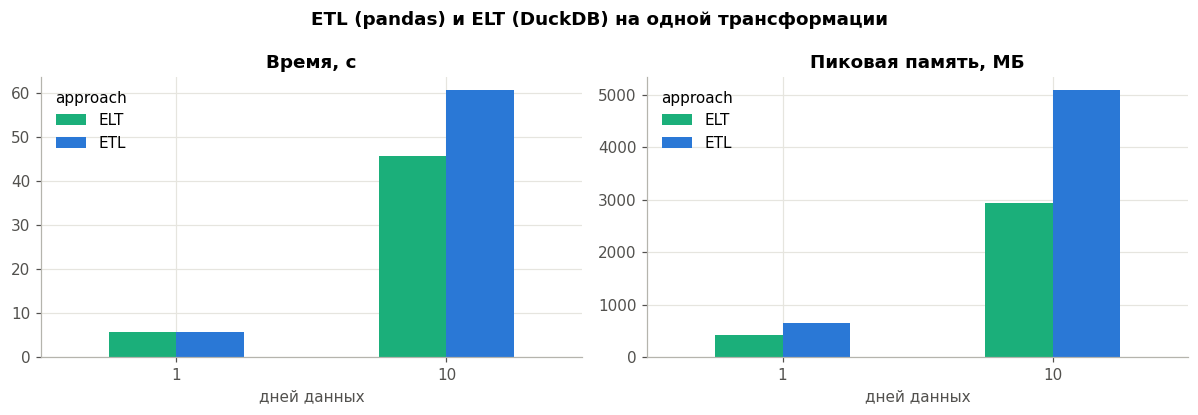

In [ ]:
def measure(cmd, budget_mb):
    """Запуск в отдельном процессе с замером времени, пиковой RSS и CPU; остановка при выходе за бюджет."""
    t0 = time.perf_counter()
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    proc, peak, cpu, killed = psutil.Process(p.pid), 0, 0.0, False
    while p.poll() is None:
        try:
            rss = proc.memory_info().rss
            ct = proc.cpu_times()
            peak, cpu = max(peak, rss), ct.user + ct.system
        except psutil.Error:
            pass
        if peak > budget_mb * 2**20:
            p.kill(); killed = True
            break
        time.sleep(0.05)
    out, err = p.communicate()
    res = json.loads(out.strip().splitlines()[-1]) if p.returncode == 0 and out.strip() else {}
    return {**res, 'wall_s': time.perf_counter() - t0, 'peak_mb': peak / 2**20, 'cpu_s': cpu,
            'status': 'не уложился в память' if killed else ('ok' if p.returncode == 0 else f'ошибка {p.returncode}')}

CMP_JSON = 'work/etl_vs_elt.json'
if os.path.exists(CMP_JSON):
    cmp_rows = json.load(open(CMP_JSON))
else:
    cmp_rows = []
    budget = psutil.virtual_memory().available / 2**20 * 0.5
    for days in ([HISTORY[0]], HISTORY):
        for mode in ('etl', 'elt'):
            out_dir = f'work/cmp_{mode}'
            shutil.rmtree(out_dir, ignore_errors=True)
            r = measure([sys.executable, 'experiments/etl_vs_elt.py', mode, LANDING, ','.join(days), out_dir,
                         str(int(budget * 0.5))], budget)
            r.update({'approach': mode.upper(), 'days': len(days)})
            cmp_rows.append(r)
            shutil.rmtree(out_dir, ignore_errors=True)
    json.dump(cmp_rows, open(CMP_JSON, 'w'))

cmp = pd.DataFrame(cmp_rows)
# стоимость запуска: vCPU-часы по процессорному времени + ГБ-часы по пиковой памяти на время запуска
cmp['cost_run_rub'] = (cmp.cpu_s / 3600 * PRICE['vm_vcpu_hour'] + cmp.peak_mb / 1024 * cmp.wall_s / 3600 * PRICE['vm_ram_gb_hour'])
cmp.loc[cmp.status != 'ok', 'cost_run_rub'] = np.nan
cmp['cost_month_rub'] = cmp.cost_run_rub * 24 * 30          # ежечасный запуск
display(cmp[['approach', 'days', 'rows_in', 'rows_out', 'status', 'wall_s', 'cpu_s', 'peak_mb', 'cost_run_rub', 'cost_month_rub']]
        .round({'wall_s': 2, 'cpu_s': 2, 'peak_mb': 0, 'cost_run_rub': 4, 'cost_month_rub': 1}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ok = cmp.assign(wall_s=cmp.wall_s.where(cmp.status == 'ok'), peak_mb=cmp.peak_mb.where(cmp.status == 'ok'))
for i, (col, title) in enumerate([('wall_s', 'Время, с'), ('peak_mb', 'Пиковая память, МБ')]):
    piv = ok.pivot(index='days', columns='approach', values=col)
    piv.plot.bar(ax=ax[i], color=[COLORS['elt'], COLORS['etl']], rot=0)
    for j, r in enumerate(cmp[cmp.status != 'ok'].itertuples()):
        x = list(piv.index).index(r.days) + (0.12 if r.approach == 'ETL' else -0.12)
        ax[i].text(x, 0, 'не уложился\nв память', ha='center', va='bottom', fontsize=8, rotation=90, color=COLORS['fail'])
    ax[i].set_title(title); ax[i].set_xlabel('дней данных'); ax[i].set_ylabel('')
fig.suptitle('ETL (pandas) и ELT (DuckDB) на одной трансформации', fontweight='bold')
plt.tight_layout(); plt.show()

**Вывод:** На одном дне данных (1,24 млн строк) ETL и ELT почти не отличаются: 5,7 с и 5,8 с, стоимость запуска 0,0023 и 0,0029 руб. ELT уже здесь требует меньше памяти (415 против 652 МБ). На 10 днях (12,8 млн строк) разница заметна: ELT быстрее (45,7 против 60,7 с), пиковая память почти вдвое ниже (2 934 против 5 086 МБ), оценка стоимости за месяц 28,2 против 35,5 руб. Процессорного времени ELT тратит больше (79 против 63 с), но выигрывает по времени и памяти. Оба подхода уложились в бюджет памяти. Результаты совпадают по числу строк (195 107 и 1 307 702), то есть сравнивается одна и та же трансформация. Эксперимент подтверждает выбор ELT: чем больше данных, тем больше выигрыш по памяти, а при росте истории pandas первым упрётся в ограничение RAM.

### 2) Спроектируйте архитектуру пайплайна:

**Создайте схему с помощью Mermaid:**

```mermaid
flowchart LR
    SRC[Источники данных<br/>сайт, приложения] --> K[Kafka<br/>часовые файлы landing]
    K --> E(Извлечение<br/>extract + idempotency_key)
    E --> V{Проверка<br/>схема, правила, GX}
    V -- битые строки --> DLQ[(DLQ<br/>Delta)]
    V -- новая схема --> REG[Реестр схем<br/>алерт]
    V --> L[Загрузка в хранилище<br/>MERGE в Delta raw_events]
    L --> T{Трансформация<br/>dbt: staging -> marts}
    T --> Q{Quality gate<br/>GX на витринах}
    Q --> P[Публикация<br/>MERGE recommendations]
    P --> A[Аналитика и сервис<br/>рекомендаций]
    T -. сбой .-> F[Fallback:<br/>предыдущая версия]
    Q -. сбой .-> F
```

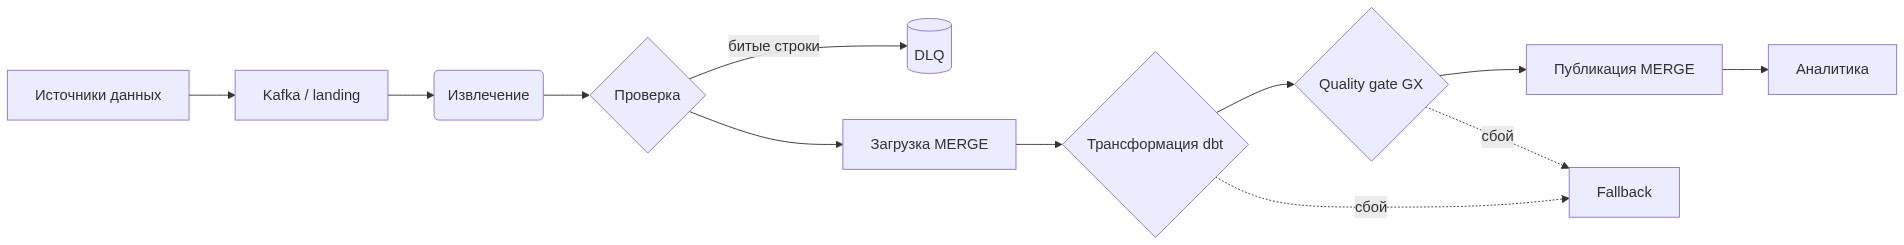

In [ ]:
MERMAID = """flowchart LR
    SRC[Источники данных] --> K[Kafka / landing]
    K --> E(Извлечение)
    E --> V{Проверка}
    V -- битые строки --> DLQ[(DLQ)]
    V --> L[Загрузка MERGE]
    L --> T{Трансформация dbt}
    T --> Q{Quality gate GX}
    Q --> P[Публикация MERGE]
    P --> A[Аналитика]
    T -. сбой .-> F[Fallback]
    Q -. сбой .-> F"""
try:
    url = 'https://mermaid.ink/img/' + base64.urlsafe_b64encode(MERMAID.encode()).decode()
    with urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'}), timeout=20) as r:
        display(Image(r.read()))
except Exception as e:
    print('Схема не отрисована (нет доступа к mermaid.ink), исходный текст Mermaid приведён выше:', e)

**Определите точки интеграции с оркестратором.** Оркестратор (Prefect) управляет каждым этапом как задачей: `detect_partitions` (аналог сенсора: находит новые часовые файлы), подпоток `ingest_partition` на каждую партицию (`extract -> validate -> load`), затем `transform` (dbt build), `quality_gate` (GX) и `publish`. Через оркестратор задаются retries, зависимости, алерты при падении (`on_failure`) и метрики каждого запуска.

**Спроектируйте обработку ошибок** (уровни из лекции):

| Уровень | Где возникает | Механизм |
|---|---|---|
| Операционные ошибки | чтение landing, запись в Delta, публикация | retries с экспоненциальной задержкой, не больше 3 повторов |
| Ошибки данных | строки с неверными типами, ценой <= 0, без сессии | DLQ (Delta-таблица) с причиной и исходной строкой, алерт при доле > 1% |
| Изменение схемы | новые или пропавшие колонки | реестр схем: лишние колонки отбрасываются с алертом, без обязательных колонок партиция уходит в DLQ |
| Ошибки трансформации и качества | dbt build, GX на витринах | публикация пропускается, в сервинге остаются предыдущие рекомендации (fallback), алерт |
| Падение запуска | любой этап после всех повторов | хук `on_failure` с алертом; следующий запуск подхватывает необработанные партиции |

### 3) Выберите технологии:

| Слой | Выбор | Почему | Альтернативы |
|---|---|---|---|
| **Для оркестрации (Airflow, Prefect, Dagster)** | Prefect 3 | flow и task как обычные функции Python, retries с экспоненциальной задержкой и подпотоки из коробки, запуск без отдельного планировщика и базы метаданных | Airflow требует scheduler, webserver и Postgres; Dagster удобен для asset-подхода, но для одного пайплайна избыточен |
| **Для трансформаций (DBT, Spark, Pandas)** | dbt + DuckDB | SQL-модели с тестами, инкрементальные модели с `unique_key`, граф зависимостей; DuckDB укладывает агрегацию 10 дней в один сервер | Spark нужен с сотен гигабайт (ЛР-2); pandas не масштабируется по памяти (сравнение выше) |
| **Для хранения (S3, Delta Lake, BigQuery)** | Delta Lake (deltalake) на объектном хранилище | MERGE для UPSERT, ACID-коммиты, история версий и time travel | BigQuery - внешний облачный сервис; голый Parquet на S3 без транзакций и MERGE |
| Качество данных | Great Expectations | проверки до загрузки и после трансформации, HTML-отчёты | только тесты dbt (нет проверок до загрузки) |
| CI/CD | GitHub Actions | окружения staging и production с ревью перед продом | GitLab CI |

### 4) Составьте матрицу требований:

| Требование | Решение | Обоснование |
|---|---|---|
| Идемпотентность | UPSERT через idempotency_key | Гарантия отсутствия дубликатов |
| Идемпотентность трансформаций | инкрементальная модель dbt `stg_events` с `unique_key` и стратегией delete+insert | повторный запуск по тем же дням перезаписывает строки, а не дописывает |
| Идемпотентность публикации | MERGE рекомендаций по `(user_id, rank)` | повтор публикации не создаёт вторых списков |
| SLA < 45 минут | часовые партиции, MERGE только затронутой партиции, алерт при превышении | длительность запуска не растёт с размером истории |
| Согласованность с production-моделью | реестр `production_model.json`, версия модели в каждой строке витрины, проверка версии перед публикацией (GX и код) | витрина, построенная другой версией модели, не публикуется |
| Fallback на предыдущие рекомендации | публикация последним шагом и только после всех проверок; Delta restore для отката | при сбое сервинг продолжает отдавать прошлую версию |
| Обработка операционных ошибок | retries=3, экспоненциальная задержка, jitter | временные сбои лечатся без человека |
| Ошибки данных | DLQ с причиной, алерт при доле > 1% | битые строки не блокируют пакет и не теряются |
| Schema drift | реестр схем, fallback на предыдущую схему, алерт | новые поля не ломают загрузку, пропажа обязательных не проходит молча |
| Качество данных | GX до загрузки и после трансформации, тесты dbt | ошибки ловятся до публикации |
| Мониторинг | метрики этапов (JSONL и формат Prometheus), алерты в журнал и Slack | видно время, объёмы и ошибки каждого запуска |
| Безопасный деплой | staging, smoke-тест, canary 5%, автоматический откат | новая версия модели не попадает ко всем пользователям без проверки |

### 5) Если выбран сценарий «Мультимодальный поток: изображения + метаданные», спроектируйте пайплайн эмбеддингов:

Выбран сценарий «Рекомендательная система», пункт для него не выполняется. В данных варианта нет изображений.

**Требования к отчету:**

- **Схема архитектуры пайплайна:** пункт 2 (Mermaid).
- **Обоснование выбора ETL vs ELT:** пункт 1.
- **Матрица требований и решений:** пункт 4.
- **Сравнение затрат для выбранных технологий:** пункт 1 (таблица и графики ETL/ELT).
- **Формат хранения эмбеддингов (Lance/Parquet) и версия энкодера (`encoder_name` / `encoder_version`):** не относится к выбранному сценарию (пункт 5). Аналог версии энкодера здесь - версия модели рекомендаций (`model_name`, `model_version`) в каждой строке витрины.

## Код пайплайна

Пайплайн оформлен как репозиторий: пакет `pipeline/` (этапы), `prefect_flows/` (оркестрация), `dbt_reco/` (трансформации), `gx/` (конфигурация Great Expectations, создаётся при первом запуске), `tests/`, `smoke_test.py`, `.github/workflows/ci.yml`. Ячейки ниже записывают эти файлы, дальше они импортируются и запускаются.

In [ ]:
for d in ('pipeline', 'prefect_flows', 'experiments', 'tests/data', '.github/workflows', 'dbt_reco/models/staging/events',
          'dbt_reco/models/marts/core', 'dbt_reco/models/marts/reco', 'dbt_reco/macros', 'dbt_reco/tests/generic'):
    os.makedirs(d, exist_ok=True)

Общие части: пути, логирование в файл, метрики (JSONL и формат Prometheus), алерты, внедрение сбоев для проверок.

In [ ]:
%%writefile pipeline/__init__.py
"""ELT-пайплайн рекомендаций (ЛР-3)."""

Writing pipeline/__init__.py


In [ ]:
%%writefile pipeline/common.py
"""Общие части пайплайна: пути, логирование, метрики, алерты, внедрение сбоев."""
import json
import logging
import os
import time
from dataclasses import dataclass
from datetime import datetime, timezone

SLA_SECONDS = 45 * 60          # задержка обработки по сценарию: < 45 минут
DLQ_ALERT_SHARE = 0.01         # алерт, если в DLQ ушло больше 1% строк пакета (обоснование в ноутбуке)
DLQ_ALERT_TOTAL = 50_000       # алерт, если DLQ накопила больше записей, чем можно разобрать вручную


@dataclass(frozen=True)
class Paths:
    root: str

    def p(self, *parts):
        return os.path.join(self.root, *parts)

    @property
    def landing(self): return self.p('landing')
    @property
    def raw(self): return self.p('lake', 'raw_events')
    @property
    def dlq(self): return self.p('lake', 'dlq')
    @property
    def reco(self): return self.p('lake', 'recommendations')
    @property
    def warehouse(self): return self.p('warehouse.duckdb')
    @property
    def logs(self): return self.p('logs')
    @property
    def state(self): return self.p('state')


def get_paths(root=None):
    paths = Paths(os.path.abspath(root or os.environ.get('LAB3_ROOT', 'work')))
    for d in (paths.logs, paths.state, paths.p('lake')):
        os.makedirs(d, exist_ok=True)
    return paths


def get_logger(paths):
    """Логгер пишет и в консоль, и в файл logs/pipeline.log (один файл на все запуски)."""
    logger = logging.getLogger('etl_pipeline')
    log_file = os.path.join(paths.logs, 'pipeline.log')
    if not any(getattr(h, 'baseFilename', None) == log_file for h in logger.handlers):
        for h in list(logger.handlers):
            if isinstance(h, logging.FileHandler):
                logger.removeHandler(h)
        fh = logging.FileHandler(log_file, encoding='utf-8')
        fh.setFormatter(logging.Formatter('%(asctime)s | %(levelname)s | %(message)s'))
        logger.addHandler(fh)
    logger.setLevel(logging.INFO)
    logger.propagate = False      # журнал только в файл, алерты дополнительно в alerts.jsonl
    return logger


def now_utc():
    return datetime.now(timezone.utc).isoformat(timespec='seconds')


def _append_jsonl(path, record):
    with open(path, 'a', encoding='utf-8') as fh:
        fh.write(json.dumps(record, ensure_ascii=False, default=str) + '\n')


def log_metric(paths, run_id, stage, **values):
    """Метрика этапа: строка в logs/metrics.jsonl и gauge в формате Prometheus (logs/metrics.prom)."""
    rec = {'ts': now_utc(), 'run_id': run_id, 'stage': stage, **values}
    _append_jsonl(os.path.join(paths.logs, 'metrics.jsonl'), rec)
    prom = os.path.join(paths.logs, 'metrics.prom')
    lines = {}
    if os.path.exists(prom):
        with open(prom, encoding='utf-8') as fh:
            for line in fh:
                if line.strip() and not line.startswith('#'):
                    lines[line.rsplit(' ', 1)[0]] = line.rstrip('\n')
    for k, v in values.items():
        if isinstance(v, (int, float)) and not isinstance(v, bool):
            key = f'pipeline_{k}{{stage="{stage}"}}'
            lines[key] = f'{key} {v}'
    with open(prom, 'w', encoding='utf-8') as fh:
        fh.write('# TYPE pipeline gauge (последние значения по этапам)\n')
        fh.write('\n'.join(sorted(lines.values())) + '\n')
    return rec


def send_alert(paths, level, kind, message, **context):
    """Алерт: запись в logs/alerts.jsonl и в лог. При заданном SLACK_WEBHOOK_URL уходит и в Slack."""
    rec = {'ts': now_utc(), 'level': level, 'kind': kind, 'message': message, **context}
    _append_jsonl(os.path.join(paths.logs, 'alerts.jsonl'), rec)
    get_logger(paths).warning(f'ALERT [{kind}] {message}')
    url = os.environ.get('SLACK_WEBHOOK_URL')
    if url:
        try:
            import requests
            requests.post(url, json={'text': f'ETL ALERT [{kind}]: {message}'}, timeout=5)
        except Exception as e:  # алерт не должен ронять пайплайн
            get_logger(paths).error(f'Slack недоступен: {e}')
    return rec


def read_jsonl(path):
    if not os.path.exists(path):
        return []
    with open(path, encoding='utf-8') as fh:
        return [json.loads(line) for line in fh if line.strip()]


class Timer:
    def __enter__(self):
        self.t0 = time.perf_counter()
        return self

    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self.t0


# Внедрение сбоев для проверки обработки ошибок: {'extract': 2} - первые 2 вызова этапа падают
FAULTS = {}


class TransientError(ConnectionError):
    """Временный сбой (сеть, хранилище): лечится повтором."""


def maybe_fail(stage):
    left = FAULTS.get(stage, 0)
    if left:
        FAULTS[stage] = left - 1
        raise TransientError(f'искусственный сбой этапа {stage} (осталось {left - 1})')


def release_memory():
    """Возвращает ОС освобождённую память (Arrow и glibc держат её у себя после больших пакетов)."""
    import ctypes
    import gc
    gc.collect()
    try:
        import pyarrow as pa
        pa.default_memory_pool().release_unused()
    except Exception:
        pass
    try:
        ctypes.CDLL('libc.so.6').malloc_trim(0)
    except Exception:
        pass

Writing pipeline/common.py


Extract: чтение часовых партиций, вычисление `idempotency_key`, состояние обработанных партиций.

In [ ]:
%%writefile pipeline/extract.py
"""Extract: чтение часовых партиций из landing-зоны и добавление идемпотентного ключа."""
import glob
import json
import os

import duckdb
import pyarrow as pa

from .common import maybe_fail

# Контракт источника (схема v1): обязательные поля нужны модели, без необязательных можно обойтись
SOURCE_COLUMNS = ['event_time', 'event_type', 'product_id', 'category_id', 'category_code',
                  'brand', 'price', 'user_id', 'user_session']
REQUIRED = ['event_time', 'event_type', 'product_id', 'price', 'user_id', 'user_session']
KEY_COLUMNS = ['event_time', 'event_type', 'product_id', 'user_id', 'user_session']


def list_partitions(paths):
    """Все часовые партиции landing в виде 'YYYY-MM-DD/HH'."""
    parts = []
    for d in glob.glob(os.path.join(paths.landing, 'dt=*', 'hr=*')):
        if glob.glob(os.path.join(d, '*.parquet')):
            dt = os.path.basename(os.path.dirname(d))[3:]
            hr = os.path.basename(d)[3:]
            parts.append(f'{dt}/{hr}')
    return sorted(parts)


def processed_state(paths):
    f = os.path.join(paths.state, 'processed.json')
    if os.path.exists(f):
        with open(f) as fh:
            return json.load(fh)
    return {}


def mark_processed(paths, partitions, status, run_id):
    state = processed_state(paths)
    for p in partitions:
        state[p] = {'status': status, 'run_id': run_id}
    with open(os.path.join(paths.state, 'processed.json'), 'w') as fh:
        json.dump(state, fh, indent=1, sort_keys=True)


def new_partitions(paths, until=None):
    """Партиции, которые ещё не обработаны (аналог сенсора: ждём новые файлы)."""
    done = processed_state(paths)
    return [p for p in list_partitions(paths) if p not in done and (until is None or p < until)]


def partition_files(paths, partition):
    """Партиция 'YYYY-MM-DD/HH' - один час, 'YYYY-MM-DD' - все часы дня."""
    if '/' in partition:
        dt, hr = partition.split('/')
        pattern = os.path.join(paths.landing, f'dt={dt}', f'hr={hr}', '*.parquet')
    else:
        pattern = os.path.join(paths.landing, f'dt={partition}', 'hr=*', '*.parquet')
    return sorted(glob.glob(pattern))


def extract_partition(paths, partition):
    """Читает файлы партиции как есть (все поля строками) и считает idempotency_key."""
    maybe_fail('extract')
    files = partition_files(paths, partition)
    if not files:
        raise FileNotFoundError(f'нет файлов для партиции {partition}')
    con = duckdb.connect()
    try:
        con.execute("SET memory_limit='512MB'; SET threads=2")
        src = con.execute('SELECT * FROM read_parquet(?, union_by_name=true, hive_partitioning=false) LIMIT 0',
                          [files]).fetch_arrow_table()
        cols = [c for c in src.column_names]
        casts = ', '.join(f'CAST("{c}" AS VARCHAR) AS "{c}"' for c in cols)
        present_key = [c for c in KEY_COLUMNS if c in cols]
        key_expr = "md5(concat_ws('|', " + ', '.join(f'coalesce("{c}", \'\')' for c in present_key) + '))'
        tbl = con.execute(
            f'SELECT {casts}, {key_expr} AS idempotency_key, ? AS _partition '
            f'FROM read_parquet(?, union_by_name=true, hive_partitioning=false)',
            [partition, files]).fetch_arrow_table()
    finally:
        con.close()
    return tbl

Writing pipeline/extract.py


Validate: реестр схем и schema drift, построчные правила и DLQ, наборы Great Expectations.

In [ ]:
%%writefile pipeline/quality.py
"""Validate: контроль схемы (schema drift), построчные правила (DLQ) и проверки Great Expectations."""
import json
import logging
import os

import duckdb
import pandas as pd
import pyarrow as pa

from .common import now_utc, send_alert
from .extract import REQUIRED, SOURCE_COLUMNS

os.environ.setdefault('GX_ANALYTICS_ENABLED', 'False')
logging.getLogger('great_expectations').setLevel(logging.ERROR)

EVENT_TYPES = ['view', 'cart', 'purchase', 'remove_from_cart']


class SchemaDriftError(Exception):
    """Схема партиции несовместима с зарегистрированной: нет обязательных полей."""


class DataValidationError(Exception):
    """Пакет не прошёл проверки качества."""


# ---------- реестр схем и schema drift ----------

def schema_registry(paths):
    f = os.path.join(paths.state, 'schema_registry.json')
    if os.path.exists(f):
        with open(f) as fh:
            return json.load(fh)
    reg = {'active': 1, 'versions': {'1': {'columns': SOURCE_COLUMNS, 'required': REQUIRED,
                                           'registered': now_utc()}}, 'candidates': []}
    with open(f, 'w') as fh:
        json.dump(reg, fh, indent=1)
    return reg


def _save_registry(paths, reg):
    with open(os.path.join(paths.state, 'schema_registry.json'), 'w') as fh:
        json.dump(reg, fh, indent=1)


def gx_columns_check(columns, expected):
    """Проверка набора колонок через Great Expectations (ExpectTableColumnsToMatchSet)."""
    import great_expectations as gx
    ctx = gx_context()
    ds = ctx.data_sources.add_or_update_pandas('pipeline') if 'pipeline' not in ctx.data_sources.all() \
        else ctx.data_sources.get('pipeline')
    try:
        bd = ds.get_asset('schema').get_batch_definition('whole')
    except Exception:
        bd = ds.add_dataframe_asset('schema').add_batch_definition_whole_dataframe('whole')
    df = pd.DataFrame({c: pd.Series([], dtype='object') for c in columns})
    res = bd.get_batch(batch_parameters={'dataframe': df}).validate(
        gx.expectations.ExpectTableColumnsToMatchSet(column_set=expected, exact_match=True))
    mism = (res.result.get('details') or {}).get('mismatched') or {}
    return res.success, sorted(mism.get('unexpected', [])), sorted(mism.get('missing', []))


def check_schema(paths, table, run_id):
    """Сверяет схему партиции с активной версией реестра и приводит пакет к ней (fallback на прежнюю схему).

    Лишние колонки отбрасываются, недостающие необязательные заполняются NULL, о том и другом
    отправляется алерт. Нет обязательной колонки - SchemaDriftError, партиция уходит в DLQ целиком.
    """
    reg = schema_registry(paths)
    ver = reg['versions'][str(reg['active'])]
    data_cols = [c for c in table.column_names if c not in ('idempotency_key', '_partition')]
    ok, added, missing = gx_columns_check(data_cols, ver['columns'])
    report = {'schema_version': reg['active'], 'ok': ok, 'added': added, 'missing': missing}
    if ok:
        return table, report
    part = table.column('_partition')[0].as_py() if table.num_rows else '?'
    missing_req = [c for c in missing if c in ver['required']]
    if added and not any(c['columns'] == data_cols for c in reg['candidates']):
        reg['candidates'].append({'columns': data_cols, 'seen': now_utc(), 'partition': part})
        _save_registry(paths, reg)
    if missing_req:
        send_alert(paths, 'critical', 'schema_drift',
                   f'партиция {part}: нет обязательных колонок {missing_req}, лишние {added}; партиция отправлена в DLQ',
                   run_id=run_id, partition=part)
        raise SchemaDriftError(f'нет обязательных колонок {missing_req}')
    send_alert(paths, 'warning', 'schema_drift',
               f'партиция {part}: лишние колонки {added} отброшены, недостающие {missing} заполнены NULL '
               f'(применена схема v{reg["active"]})', run_id=run_id, partition=part)
    cols = []
    for c in ver['columns']:
        cols.append(table.column(c) if c in table.column_names else pa.nulls(table.num_rows, pa.string()))
    cols += [table.column('idempotency_key'), table.column('_partition')]
    return pa.table(cols, names=ver['columns'] + ['idempotency_key', '_partition']), report


def drift_to_dlq(table, reason, run_id):
    """Вся партиция с несовместимой схемой превращается в записи DLQ (исходная строка в payload)."""
    con = duckdb.connect()
    try:
        con.register('b', table)
        return con.execute(f"""
            SELECT md5(idempotency_key || '|' || ?) AS dlq_key, idempotency_key, ? AS reason,
                   to_json(b)::VARCHAR AS payload,
                   _partition, ? AS run_id, ? AS detected_at
            FROM b""", [reason, reason, run_id, now_utc()]).fetch_arrow_table()
    finally:
        con.close()


# ---------- построчные правила ----------

ROW_RULES = """
    CASE WHEN ts IS NULL THEN 'bad_event_time'
         WHEN event_type IS NULL OR event_type NOT IN ('view', 'cart', 'purchase', 'remove_from_cart')
              THEN 'bad_event_type'
         WHEN pid IS NULL OR pid <= 0 THEN 'bad_product_id'
         WHEN uid IS NULL OR uid <= 0 THEN 'bad_user_id'
         WHEN pr IS NULL THEN 'bad_price'
         WHEN pr <= 0 THEN 'price_not_positive'
         WHEN user_session IS NULL OR user_session = '' THEN 'no_session'
    END"""


def split_rows(table, run_id):
    """Делит пакет на валидные строки (типизированные, без дублей) и записи для DLQ."""
    con = duckdb.connect()
    try:
        con.execute("SET memory_limit='768MB'; SET threads=2")
        con.register('b', table)
        con.execute(f"""
            CREATE TEMP TABLE c AS
            SELECT *, {ROW_RULES} AS reason FROM (
                SELECT *, TRY_STRPTIME(event_time, '%Y-%m-%d %H:%M:%S UTC') AS ts,
                       TRY_CAST(product_id AS BIGINT) AS pid, TRY_CAST(category_id AS BIGINT) AS cid,
                       TRY_CAST(price AS DOUBLE) AS pr, TRY_CAST(user_id AS BIGINT) AS uid
                FROM b)""")
        con.unregister('b')
        rejected = con.execute("""
            SELECT md5(idempotency_key || '|' || reason) AS dlq_key, idempotency_key, reason,
                   to_json({'event_time': event_time, 'event_type': event_type, 'product_id': product_id,
                            'category_id': category_id, 'category_code': category_code, 'brand': brand,
                            'price': price, 'user_id': user_id, 'user_session': user_session})::VARCHAR AS payload,
                   _partition, ? AS run_id, ? AS detected_at
            FROM c WHERE reason IS NOT NULL""", [run_id, now_utc()]).fetch_arrow_table()
        n_valid = con.execute('SELECT count(*) FROM c WHERE reason IS NULL').fetchone()[0]
        valid = con.execute("""
            SELECT idempotency_key, ts AS event_time, CAST(ts AS DATE) AS event_date,
                   CAST(hour(ts) AS TINYINT) AS event_hour, event_type,
                   pid AS product_id, cid AS category_id, category_code, brand, pr AS price,
                   uid AS user_id, user_session
            FROM c WHERE reason IS NULL
            QUALIFY row_number() OVER (PARTITION BY idempotency_key ORDER BY _partition) = 1
            ORDER BY event_time""").fetch_arrow_table()
    finally:
        con.close()
    return valid, rejected, {'rows_valid_before_dedup': n_valid, 'duplicates_in_batch': n_valid - valid.num_rows}


# ---------- Great Expectations: наборы проверок, чекпоинты, Data Docs ----------

def _set_no_progress(ctx):
    try:
        from great_expectations.data_context.types.base import ProgressBarsConfig
        ctx.variables.progress_bars = ProgressBarsConfig(globally=False)
    except Exception:
        pass


def gx_context(gx_root=None):
    import great_expectations as gx
    root = os.path.abspath(gx_root or os.environ.get('LAB3_GX_ROOT', '.'))
    ctx = gx.get_context(mode='file', project_root_dir=root)
    _set_no_progress(ctx)
    return ctx


def suite_definitions(k=10, model_version='1.0', min_price=0.0, max_price=100_000.0):
    """Наборы ожиданий: до загрузки (raw_batch) и после трансформации (recommendations, fact_sales)."""
    import great_expectations as gx
    E = gx.expectations
    return {
        'raw_batch': [
            *[E.ExpectColumnValuesToNotBeNull(column=c) for c in
              ('idempotency_key', 'event_time', 'event_type', 'product_id', 'user_id', 'price', 'user_session')],
            E.ExpectColumnValuesToBeInSet(column='event_type', value_set=EVENT_TYPES),
            E.ExpectColumnValuesToBeBetween(column='price', min_value=min_price, max_value=max_price,
                                            strict_min=True),
            E.ExpectColumnValuesToBeBetween(column='user_id', min_value=1),
            E.ExpectColumnValuesToBeUnique(column='idempotency_key'),
        ],
        'recommendations': [
            *[E.ExpectColumnValuesToNotBeNull(column=c) for c in ('user_id', 'rank', 'product_id', 'model_version')],
            E.ExpectColumnValuesToBeBetween(column='rank', min_value=1, max_value=k),
            E.ExpectCompoundColumnsToBeUnique(column_list=['user_id', 'rank']),
            E.ExpectCompoundColumnsToBeUnique(column_list=['user_id', 'product_id']),
            E.ExpectColumnValuesToBeInSet(column='model_version', value_set=[model_version]),
            # связь между таблицами: товар рекомендации есть в dim_products
            E.ExpectColumnValuesToBeInSet(column='product_in_dim', value_set=[True]),
        ],
        'fact_sales': [
            E.ExpectColumnValuesToNotBeNull(column='sale_id'),
            E.ExpectColumnValuesToBeUnique(column='sale_id'),
            E.ExpectColumnValuesToBeBetween(column='amount_usd', min_value=0, strict_min=True),
            E.ExpectColumnValuesToNotBeNull(column='amount_rub'),
            # связи между таблицами: fact_sales -> dim_products, fact_sales -> dim_users
            E.ExpectColumnValuesToBeInSet(column='product_in_dim', value_set=[True]),
            E.ExpectColumnValuesToBeInSet(column='user_in_dim', value_set=[True]),
        ],
    }


def ensure_gx_objects(ctx, **suite_kwargs):
    """Создаёт (или обновляет) источник, наборы, определения валидаций и чекпоинты в контексте GX."""
    import great_expectations as gx
    ds = ctx.data_sources.get('pipeline') if 'pipeline' in ctx.data_sources.all() \
        else ctx.data_sources.add_pandas('pipeline')
    for name, exps in suite_definitions(**suite_kwargs).items():
        try:
            asset = ds.get_asset(name)
        except Exception:
            asset = ds.add_dataframe_asset(name)
        try:
            bd = asset.get_batch_definition('whole')
        except Exception:
            bd = asset.add_batch_definition_whole_dataframe('whole')
        suite = gx.ExpectationSuite(name=name, expectations=exps)
        suite = ctx.suites.add_or_update(suite)
        vd = ctx.validation_definitions.add_or_update(gx.ValidationDefinition(name=f'{name}_vd', data=bd, suite=suite))
        # Data Docs пересобираются целиком на каждом чекпоинте, поэтому обновляются только проверками витрин
        # (раз за запуск), а не проверкой каждой партиции
        actions = [] if name == 'raw_batch' else [gx.checkpoint.UpdateDataDocsAction(name='update_docs')]
        ctx.checkpoints.add_or_update(gx.Checkpoint(
            name=f'{name}_checkpoint', validation_definitions=[vd], actions=actions,
            result_format={'result_format': 'SUMMARY', 'partial_unexpected_count': 5}))


def run_checkpoint(ctx, name, df):
    """Запускает чекпоинт набора name на DataFrame и возвращает краткий отчёт."""
    res = ctx.checkpoints.get(f'{name}_checkpoint').run(batch_parameters={'dataframe': df})
    vr = next(iter(res.run_results.values()))
    failed = []
    for r in vr.results:
        if not r.success:
            cfg = r.expectation_config
            kw = cfg.kwargs
            failed.append({'expectation': cfg.type, 'column': kw.get('column') or kw.get('column_list'),
                           'unexpected_count': r.result.get('unexpected_count'),
                           'unexpected_percent': r.result.get('unexpected_percent'),
                           'examples': r.result.get('partial_unexpected_list')})
    st = vr.statistics
    return {'suite': name, 'success': bool(res.success), 'evaluated': st['evaluated_expectations'],
            'successful': st['successful_expectations'], 'success_percent': st['success_percent'],
            'failed': failed}

Writing pipeline/quality.py


Load: Delta Lake, MERGE, time travel и откат.

In [ ]:
%%writefile pipeline/storage.py
"""Load: Delta Lake с UPSERT (MERGE), история версий и time travel."""
import multiprocessing as mp
import os
import resource
from concurrent.futures import ProcessPoolExecutor
from concurrent.futures.process import BrokenProcessPool

import pyarrow as pa
from deltalake import DeltaTable, write_deltalake

RAW_SCHEMA = pa.schema([
    ('idempotency_key', pa.string()), ('event_time', pa.timestamp('us')), ('event_date', pa.date32()),
    ('event_hour', pa.int8()), ('event_type', pa.string()), ('product_id', pa.int64()),
    ('category_id', pa.int64()), ('category_code', pa.string()), ('brand', pa.string()), ('price', pa.float64()),
    ('user_id', pa.int64()), ('user_session', pa.string()),
])
DLQ_SCHEMA = pa.schema([
    ('dlq_key', pa.string()), ('idempotency_key', pa.string()), ('reason', pa.string()),
    ('payload', pa.string()), ('_partition', pa.string()), ('run_id', pa.string()), ('detected_at', pa.string()),
])
RECO_SCHEMA = pa.schema([
    ('user_id', pa.int64()), ('rank', pa.int32()), ('product_id', pa.int64()), ('category_id', pa.int64()),
    ('score', pa.float64()), ('source', pa.string()), ('model_name', pa.string()),
    ('model_version', pa.string()), ('generated_at', pa.timestamp('us')), ('run_id', pa.string()),
    ('user_bucket', pa.int8()),
])
RECO_BUCKETS = 8   # корзины user_id % 8: публикация и MERGE идут по корзине, память ограничена её размером

TABLES = {
    'raw': (RAW_SCHEMA, ['event_date', 'event_hour'],
            't.idempotency_key = s.idempotency_key AND t.event_date = s.event_date AND t.event_hour = s.event_hour'),
    'dlq': (DLQ_SCHEMA, None, 't.dlq_key = s.dlq_key'),
    'reco': (RECO_SCHEMA, ['user_bucket'], 't.user_id = s.user_id AND t.rank = s.rank'),
}


def ensure_table(path, schema, partition_by=None):
    if not os.path.exists(os.path.join(path, '_delta_log')):
        DeltaTable.create(path, schema=schema, partition_by=partition_by, mode='ignore')
    return DeltaTable(path)


def _upsert(path, kind, data):
    schema, part, predicate = TABLES[kind]
    dt = ensure_table(path, schema, part)
    data = data.select(schema.names).cast(schema)
    if data.num_rows == 0:
        return {'num_source_rows': 0, 'num_target_rows_inserted': 0, 'num_target_rows_updated': 0,
                'version': dt.version()}
    if part:
        # литералы партиций в условии: delta-rs читает только затронутые партиции, а не всю таблицу
        import pyarrow.compute as pc
        conds = []
        for c in part:
            vals = pc.unique(data.column(c)).to_pylist()
            lit = ', '.join(f"'{v}'" if not isinstance(v, int) else str(v) for v in vals)
            conds.append(f't.{c} IN ({lit})')
        predicate = ' AND '.join(conds) + ' AND ' + predicate
    res = (dt.merge(source=data, predicate=predicate, source_alias='s', target_alias='t')
             .when_matched_update_all().when_not_matched_insert_all().execute())
    res['version'] = DeltaTable(path).version()
    res['worker_peak_mb'] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024)
    return res


# delta-rs не возвращает память после MERGE (около 30 МБ на коммит), поэтому запись идёт
# в отдельном процессе, который пересоздаётся каждые 4 коммита
_POOL = None


def _pool():
    global _POOL
    if _POOL is None:
        _POOL = ProcessPoolExecutor(max_workers=1, mp_context=mp.get_context('spawn'), max_tasks_per_child=4)
    return _POOL


def shutdown_pool():
    """Останавливает процесс записи (перед тяжёлыми этапами, чтобы не держать его память)."""
    global _POOL
    if _POOL is not None:
        _POOL.shutdown(wait=True)
        _POOL = None


def upsert(path, kind, data):
    """MERGE INTO target USING source ON key WHEN MATCHED UPDATE * WHEN NOT MATCHED INSERT *."""
    global _POOL
    try:
        return _pool().submit(_upsert, path, kind, data).result()
    except BrokenProcessPool:
        _POOL = None
        raise


def _publish_bucket(warehouse, path, bucket, run_id):
    import duckdb
    con = duckdb.connect(warehouse, read_only=True)
    try:
        tbl = con.execute(f"""SELECT *, ? AS run_id, CAST(user_id % {RECO_BUCKETS} AS TINYINT) AS user_bucket
                              FROM user_recommendations WHERE user_id % {RECO_BUCKETS} = ?""",
                          [run_id, bucket]).fetch_arrow_table()
    finally:
        con.close()
    return _upsert(path, 'reco', tbl)


def publish_recommendations(warehouse, path, run_id):
    """MERGE витрины user_recommendations в таблицу сервинга по корзинам пользователей."""
    global _POOL
    total = {'num_source_rows': 0, 'num_target_rows_inserted': 0, 'num_target_rows_updated': 0}
    try:
        for b in range(RECO_BUCKETS):
            r = _pool().submit(_publish_bucket, warehouse, path, b, run_id).result()
            for k in total:
                total[k] += r[k]
            total['version'] = r['version']
    except BrokenProcessPool:
        _POOL = None
        raise
    return total


def insert_only(path, kind, data):
    """Неидемпотентная загрузка (обычный INSERT/append) - только для сравнения с MERGE."""
    schema, part, _ = TABLES[kind]
    ensure_table(path, schema, part)
    write_deltalake(path, data.select(schema.names).cast(schema), mode='append', partition_by=part)
    return DeltaTable(path).version()


def table_version(path):
    return DeltaTable(path).version() if os.path.exists(os.path.join(path, '_delta_log')) else -1


def history(path):
    return DeltaTable(path).history()


def read_version(path, version=None, columns=None):
    """Time travel: чтение таблицы в состоянии на версию version (None - текущая)."""
    dt = DeltaTable(path)
    if version is not None:
        dt.load_as_version(version)
    return dt.to_pyarrow_table(columns=columns)


def restore(path, version):
    """Откат таблицы к версии version (новый коммит RESTORE, история сохраняется)."""
    return DeltaTable(path).restore(version)

Writing pipeline/storage.py


Transform: запуск dbt и реестр production-модели.

In [ ]:
%%writefile pipeline/transform.py
"""Transform (ELT): запуск dbt-проекта поверх DuckDB и чтение витрин."""
import json
import os
import subprocess
import sys

import duckdb
import psutil

from .common import maybe_fail

DBT_DIR = os.environ.get('LAB3_DBT_DIR', 'dbt_reco')

# Production-модель, с которой должны быть согласованы витрины (реестр в state/production_model.json)
PRODUCTION_MODEL = {'model_name': 'popular_in_category', 'model_version': '1.0', 'k': 10, 'window_days': 10,
                    'cart_weight': 0, 'exclude_bought': True}


def production_model(paths):
    f = os.path.join(paths.state, 'production_model.json')
    if not os.path.exists(f):
        with open(f, 'w') as fh:
            json.dump(PRODUCTION_MODEL, fh, indent=1)
    with open(f) as fh:
        return json.load(fh)


def dbt_env(paths, warehouse=None):
    env = dict(os.environ)
    total_mb = psutil.virtual_memory().total / 2**20
    mem_mb = int(total_mb * (0.12 if total_mb >= 8 * 1024 else 0.08))   # при малой RAM DuckDB чаще пишет на диск
    env.update({
        'LAB3_WAREHOUSE': os.path.abspath(warehouse or paths.warehouse),
        'LAB3_RAW_PATH': os.path.abspath(paths.raw),
        'LAB3_DUCKDB_MEM': f'{mem_mb}MB',
        'LAB3_DBT_THREADS': '2' if psutil.virtual_memory().total >= 8 * 2**30 else '1',
        'DBT_PROFILES_DIR': os.path.abspath(DBT_DIR),
        'DBT_SEND_ANONYMOUS_USAGE_STATS': 'false',
    })
    return env


def run_dbt(paths, args, dbt_vars=None, warehouse=None, check=True):
    """dbt в отдельном процессе: файл DuckDB открыт только у одного писателя."""
    maybe_fail('transform')
    cmd = [sys.executable, '-m', 'dbt.cli.main', *args, '--project-dir', os.path.abspath(DBT_DIR)]
    if dbt_vars:
        cmd += ['--vars', json.dumps(dbt_vars)]
    p = subprocess.run(cmd, env=dbt_env(paths, warehouse), capture_output=True, text=True)
    out = p.stdout + p.stderr
    results = []
    rr = os.path.join(DBT_DIR, 'target', 'run_results.json')
    if os.path.exists(rr) and args[0] in ('build', 'run', 'test'):
        with open(rr) as fh:
            for r in json.load(fh)['results']:
                results.append({'node': r['unique_id'], 'status': r['status'],
                                'seconds': round(r['execution_time'], 2),
                                'failures': r.get('failures'), 'message': r.get('message')})
    if check and p.returncode != 0:
        raise RuntimeError(f'dbt {args[0]} завершился с кодом {p.returncode}:\n' + out[-3000:])
    return {'returncode': p.returncode, 'results': results, 'log': out}


def model_vars(paths, as_of, batch_start, model=None):
    model = model or production_model(paths)
    return {'as_of': as_of, 'batch_start': batch_start, 'k': model['k'], 'window_days': model['window_days'],
            'model_name': model['model_name'], 'model_version': model['model_version'],
            'cart_weight': model.get('cart_weight', 0), 'exclude_bought': model.get('exclude_bought', True)}


def query(paths, sql, params=None, warehouse=None):
    con = duckdb.connect(warehouse or paths.warehouse, read_only=True)
    try:
        return con.execute(sql, params or []).fetch_arrow_table()
    finally:
        con.close()

Writing pipeline/transform.py


CI/CD: сборка версии в staging, smoke-тест, canary, продвижение и откат; команды для GitHub Actions.

In [ ]:
%%writefile pipeline/deploy.py
"""CI/CD модели рекомендаций: сборка версии в staging, smoke-тест, canary, продвижение и откат."""
import json
import os
import time

import duckdb
import numpy as np

from . import storage as st
from . import transform as tr
from .common import now_utc, send_alert


def build_version(paths, model, warehouse, as_of, batch_start):
    """Сборка версии модели в отдельном хранилище (staging): dbt build со всеми тестами."""
    res = tr.run_dbt(paths, ['build'], tr.model_vars(paths, as_of, batch_start, model), warehouse=warehouse,
                     check=False)
    failed = [r for r in res['results'] if r['status'] in ('fail', 'error')]
    return {'ok': res['returncode'] == 0, 'nodes': len(res['results']), 'failed': failed}


def smoke_test(warehouse, k=10, n_lookups=300, seed=42, latency_ms=100.0, min_coverage=0.99):
    """Есть рекомендации, у пользователей полный список из k товаров, поиск по user_id укладывается в SLA."""
    con = duckdb.connect(warehouse, read_only=True)
    try:
        users, rows, full = con.execute(f"""
            SELECT count(DISTINCT user_id), count(*),
                   count(*) FILTER (WHERE n = {k}) FROM (
                SELECT user_id, count(*) AS n FROM user_recommendations GROUP BY user_id)""").fetchone()
        ids = [r[0] for r in con.execute('SELECT DISTINCT user_id FROM user_recommendations ORDER BY user_id').fetchall()]
        rng = np.random.default_rng(seed)
        sample = rng.choice(ids, size=min(n_lookups, len(ids)), replace=False) if ids else []
        lat = []
        for uid in sample:
            t = time.perf_counter()
            con.execute('SELECT product_id FROM user_recommendations WHERE user_id = ? ORDER BY rank',
                        [int(uid)]).fetchall()
            lat.append((time.perf_counter() - t) * 1000)
    finally:
        con.close()
    coverage = full / users if users else 0.0
    p50, p99 = (float(np.percentile(lat, 50)), float(np.percentile(lat, 99))) if lat else (np.nan, np.nan)
    return {'users': users, 'rows': rows, 'full_list_share': coverage, 'lookup_p50_ms': p50, 'lookup_p99_ms': p99,
            'passed': bool(users > 0 and coverage >= min_coverage and p99 < latency_ms)}


def hit_rate(landing, warehouse, as_of, horizon_hours=24, canary_share=None):
    """HitRate@k: доля пользователей, которые в следующие horizon_hours часов взаимодействовали
    хотя бы с одним рекомендованным товаром (any - любое событие, purchase - покупка)."""
    con = duckdb.connect(warehouse, read_only=True)
    try:
        filt = f'WHERE user_id % 100 < {canary_share}' if canary_share else ''
        con.execute(f'CREATE TEMP TABLE r AS SELECT user_id, product_id FROM user_recommendations {filt}')
        con.execute(f"""
            CREATE TEMP TABLE f AS
            SELECT DISTINCT TRY_CAST(user_id AS BIGINT) AS user_id, TRY_CAST(product_id AS BIGINT) AS product_id,
                   event_type
            FROM read_parquet('{landing}/dt=*/hr=*/*.parquet', hive_partitioning=false, union_by_name=true)
            WHERE event_time >= ? AND event_time < ?""",
                    [f'{as_of} UTC', f'{_shift(as_of, horizon_hours)} UTC'])
        users, hit_any, hit_buy = con.execute("""
            SELECT count(DISTINCT r.user_id),
                   count(DISTINCT r.user_id) FILTER (WHERE f.user_id IS NOT NULL),
                   count(DISTINCT r.user_id) FILTER (WHERE f.event_type = 'purchase')
            FROM r LEFT JOIN f USING (user_id, product_id)""").fetchone()
    finally:
        con.close()
    return {'users': users, 'hit_rate_any': hit_any / users if users else 0.0,
            'hit_rate_purchase': hit_buy / users if users else 0.0}


def _shift(ts, hours):
    from datetime import datetime, timedelta
    return (datetime.strptime(ts, '%Y-%m-%d %H:%M:%S') + timedelta(hours=hours)).strftime('%Y-%m-%d %H:%M:%S')


def canary(paths, prod_wh, cand_wh, as_of, share=5, tolerance=0.0):
    """Canary: новая версия обслуживает share% пользователей (user_id % 100 < share);
    решение принимается по HitRate на этих же пользователях у текущей и новой версии."""
    prod = hit_rate(paths.landing, prod_wh, as_of, canary_share=share)
    cand = hit_rate(paths.landing, cand_wh, as_of, canary_share=share)
    promote = cand['hit_rate_any'] >= prod['hit_rate_any'] - tolerance
    return {'share_percent': share, 'production': prod, 'candidate': cand,
            'delta_hit_rate_any': cand['hit_rate_any'] - prod['hit_rate_any'], 'promote': bool(promote)}


def model_history(paths):
    f = os.path.join(paths.state, 'model_history.json')
    if os.path.exists(f):
        with open(f) as fh:
            return json.load(fh)
    return []


def promote(paths, model, reason):
    """Продвижение версии в production: запись реестра модели и истории версий."""
    hist = model_history(paths)
    hist.append({'ts': now_utc(), 'action': 'promote', 'model': model, 'reason': reason,
                 'reco_version_before': st.table_version(paths.reco)})
    with open(os.path.join(paths.state, 'model_history.json'), 'w') as fh:
        json.dump(hist, fh, indent=1)
    with open(os.path.join(paths.state, 'production_model.json'), 'w') as fh:
        json.dump(model, fh, indent=1)


def rollback(paths, reason):
    """Автоматический откат: прежняя версия модели в реестре и прежняя версия таблицы сервинга (Delta restore)."""
    hist = model_history(paths)
    last = next((h for h in reversed(hist) if h['action'] == 'promote'), None)
    if last is None:
        return None
    prev = next((h['model'] for h in reversed(hist[:hist.index(last)]) if h['action'] == 'promote'),
                tr.PRODUCTION_MODEL)
    with open(os.path.join(paths.state, 'production_model.json'), 'w') as fh:
        json.dump(prev, fh, indent=1)
    restored_to = last['reco_version_before']
    if restored_to >= 0:
        st.restore(paths.reco, restored_to)
    hist.append({'ts': now_utc(), 'action': 'rollback', 'model': prev, 'reason': reason,
                 'reco_restored_to': restored_to})
    with open(os.path.join(paths.state, 'model_history.json'), 'w') as fh:
        json.dump(hist, fh, indent=1)
    send_alert(paths, 'critical', 'rollback', f'откат на модель {prev["model_version"]}: {reason}')
    return {'model': prev, 'reco_restored_to': restored_to}

Writing pipeline/deploy.py


In [ ]:
%%writefile pipeline/ci.py
"""Команды CI/CD: их вызывают шаги .github/workflows/ci.yml (python -m pipeline.ci <команда>)."""
import argparse
import json
import os
import sys

from . import deploy, quality as q, transform as tr
from .common import get_paths


def last_batch(paths):
    with open(os.path.join(paths.state, 'last_transform.json')) as fh:
        return json.load(fh)


def candidate(paths):
    with open(os.path.join(paths.state, 'candidate_model.json')) as fh:
        return json.load(fh)


def run_gx(paths, warehouse=None):
    model = tr.production_model(paths)
    ctx = q.gx_context()
    q.ensure_gx_objects(ctx, k=model['k'], model_version=model['model_version'])
    reco = tr.query(paths, """SELECT r.user_id, r.rank, r.product_id, r.model_version,
                                     p.product_id IS NOT NULL AS product_in_dim
                              FROM user_recommendations r LEFT JOIN dim_products p USING (product_id)""",
                    warehouse=warehouse).to_pandas()
    return q.run_checkpoint(ctx, 'recommendations', reco)


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument('cmd', choices=['sample-run', 'gx', 'dbt-test', 'deploy-staging', 'smoke', 'canary', 'promote',
                                    'rollback'])
    ap.add_argument('--root', default=os.environ.get('LAB3_ROOT', 'work'))
    ap.add_argument('--share', type=int, default=5)
    args = ap.parse_args(argv)
    os.environ['LAB3_ROOT'] = os.path.abspath(args.root)
    paths = get_paths(args.root)
    staging = paths.p('staging.duckdb')
    if args.cmd == 'sample-run':
        import shutil
        from prefect_flows.etl_pipeline import reco_etl
        from .extract import list_partitions
        shutil.copytree(os.path.join('tests', 'data', 'landing'), paths.landing, dirs_exist_ok=True)
        res = reco_etl(partitions=list_partitions(paths))
        ok = res['status'] == 'ok'
    elif args.cmd == 'gx':
        res = run_gx(paths)
        ok = res['success']
    elif args.cmd == 'dbt-test':
        b = last_batch(paths)
        res = tr.run_dbt(paths, ['test'], tr.model_vars(paths, b['as_of'], b['batch_start']), check=False)
        res = {'returncode': res['returncode'], 'failed': [r for r in res['results'] if r['status'] != 'pass']}
        ok = res['returncode'] == 0
    elif args.cmd == 'deploy-staging':
        b = last_batch(paths)
        res = deploy.build_version(paths, candidate(paths), staging, b['as_of'], b['batch_start'])
        ok = res['ok']
    elif args.cmd == 'smoke':
        res = deploy.smoke_test(staging)
        ok = res['passed']
    elif args.cmd == 'canary':
        res = deploy.canary(paths, paths.warehouse, staging, last_batch(paths)['as_of'], share=args.share)
        ok = res['promote']
    elif args.cmd == 'promote':
        deploy.promote(paths, candidate(paths), 'canary passed')
        res, ok = {'promoted': candidate(paths)}, True
    else:
        res = deploy.rollback(paths, 'CI: провал canary или деплоя')
        ok = True
    print(json.dumps(res, ensure_ascii=False, default=str, indent=1))
    return 0 if ok else 1


if __name__ == '__main__':
    sys.exit(main())

Writing pipeline/ci.py


Оркестрация в Prefect.

In [ ]:
%%writefile prefect_flows/__init__.py
"""Оркестрация пайплайна рекомендаций в Prefect."""

Writing prefect_flows/__init__.py


In [ ]:
%%writefile prefect_flows/etl_pipeline.py
"""Оркестрация ELT-пайплайна рекомендаций в Prefect.

Граф: detect -> [ingest_partition: extract -> validate -> load (MERGE raw + DLQ)] x N партиций
      -> transform (dbt build) -> quality_gate (GX) -> publish (MERGE рекомендаций).
При сбое transform/quality_gate/publish в сервинге остаются предыдущие рекомендации (fallback).
"""
import json
import os
import time
import uuid
from datetime import datetime, timedelta
from typing import Optional

import pyarrow as pa
from prefect import flow, get_run_logger, task
from prefect.cache_policies import NO_CACHE
from prefect.context import get_run_context
from prefect.tasks import exponential_backoff

from pipeline import common
from pipeline import extract as ex
from pipeline import quality as q
from pipeline import storage as st
from pipeline import transform as tr
from pipeline.common import Timer, get_logger, get_paths, log_metric, send_alert

# В production задержки в минутах (backoff_factor=60); в работе секунды, чтобы проверка не ждала
BACKOFF = float(os.environ.get('LAB3_BACKOFF', '1'))
RETRY = dict(retries=3, retry_delay_seconds=exponential_backoff(backoff_factor=BACKOFF),
             retry_jitter_factor=0.2, cache_policy=NO_CACHE)


def _log(msg):
    try:
        get_run_logger().info(msg)
    except Exception:
        pass
    get_logger(get_paths()).info(msg)


@task(name='detect_partitions', cache_policy=NO_CACHE)
def detect_partitions(until=None):
    paths = get_paths()
    parts = ex.new_partitions(paths, until)
    pending = [p for p, s in ex.processed_state(paths).items() if s['status'] == 'loaded']
    _log(f'новых партиций: {len(parts)}, ждут трансформации: {len(pending)}')
    return parts, pending


@task(name='extract', **RETRY)
def extract_task(partition, run_id):
    paths = get_paths()
    with Timer() as t:
        tbl = ex.extract_partition(paths, partition)
    log_metric(paths, run_id, 'extract', partition=partition, rows=tbl.num_rows, seconds=round(t.seconds, 3))
    _log(f'extract {partition}: {tbl.num_rows} строк за {t.seconds:.2f} с')
    return tbl


@task(name='validate', cache_policy=NO_CACHE)
def validate_task(tbl, partition, run_id):
    """Схема -> построчные правила (DLQ) -> Great Expectations перед загрузкой."""
    paths = get_paths()
    with Timer() as t:
        try:
            tbl, schema_report = q.check_schema(paths, tbl, run_id)
        except q.SchemaDriftError as e:
            rejected = q.drift_to_dlq(tbl, f'schema_drift: {e}', run_id)
            log_metric(paths, run_id, 'validate', partition=partition, rows_in=tbl.num_rows, rows_valid=0,
                       rows_dlq=rejected.num_rows, schema_drift=1)
            return {'partition': partition, 'valid': None, 'rejected': rejected,
                    'report': {'rows_in': tbl.num_rows, 'rows_valid': 0, 'rows_dlq': rejected.num_rows,
                               'schema': 'drift_quarantined', 'gx': None}}
        valid, rejected, rep = q.split_rows(tbl, run_id)
        gx_rep = None
        if valid.num_rows:
            ctx = q.gx_context()
            cols = ['idempotency_key', 'event_time', 'event_type', 'product_id', 'user_id', 'price', 'user_session']
            gx_rep = q.run_checkpoint(ctx, 'raw_batch', valid.select(cols).to_pandas())
            if not gx_rep['success']:
                send_alert(paths, 'critical', 'gx_failed', f'партиция {partition}: проверки GX не пройдены '
                           f'({gx_rep["failed"]}), партиция отправлена в DLQ', run_id=run_id)
                bad = q.drift_to_dlq(tbl, 'gx_failed', run_id)
                rejected = pa.concat_tables([rejected, bad.select(rejected.column_names)])
                valid = None
    n_dlq = rejected.num_rows
    share = n_dlq / max(tbl.num_rows, 1)
    report = {'rows_in': tbl.num_rows, 'rows_valid': valid.num_rows if valid is not None else 0,
              'rows_dlq': n_dlq, 'dlq_share': share, 'duplicates_in_batch': rep['duplicates_in_batch'],
              'schema': 'ok' if schema_report['ok'] else 'drift_fallback', 'gx': gx_rep,
              'seconds': round(t.seconds, 3)}
    log_metric(paths, run_id, 'validate', partition=partition, rows_in=tbl.num_rows, rows_valid=report['rows_valid'],
               rows_dlq=n_dlq, duplicates=rep['duplicates_in_batch'], seconds=round(t.seconds, 3),
               gx_success_percent=gx_rep['success_percent'] if gx_rep else None)
    if share > common.DLQ_ALERT_SHARE:
        send_alert(paths, 'warning', 'dlq_share', f'партиция {partition}: в DLQ {n_dlq} строк ({share:.2%}) '
                   f'при пороге {common.DLQ_ALERT_SHARE:.0%}', run_id=run_id)
    return {'partition': partition, 'valid': valid, 'rejected': rejected, 'report': report}


@flow(name='ingest_partition', flow_run_name='ingest-{partition}')
def ingest_partition(partition, run_id):
    """Подпоток для повторяющегося шаблона (аналог SubDAG): extract -> validate -> load одной партиции.
    Наружу отдаётся только отчёт, таблицы освобождаются сразу после загрузки."""
    tbl = extract_task(partition, run_id)
    res = validate_task(tbl, partition, run_id)
    del tbl
    loaded = load_task(res, run_id)
    return {'partition': partition, 'report': res['report'], 'load': loaded}


@task(name='load', **RETRY)
def load_task(res, run_id):
    """MERGE валидных строк партиции в raw_events, затем MERGE отклонённых в DLQ. Оба шага идемпотентны."""
    paths = get_paths()
    with Timer() as t:
        if res['valid'] is not None and res['valid'].num_rows:
            raw = st.upsert(paths.raw, 'raw', res['valid'])
        else:
            raw = {'num_source_rows': 0, 'num_target_rows_inserted': 0, 'num_target_rows_updated': 0,
                   'version': st.table_version(paths.raw)}
        common.maybe_fail('load')   # точка сбоя: raw уже записан, DLQ ещё нет
        if res['rejected'].num_rows:
            dlq = st.upsert(paths.dlq, 'dlq', res['rejected'])
        else:
            dlq = {'num_target_rows_inserted': 0, 'version': st.table_version(paths.dlq)}
    log_metric(paths, run_id, 'load', partition=res['partition'], rows=raw['num_source_rows'],
               inserted=raw['num_target_rows_inserted'], updated=raw['num_target_rows_updated'],
               dlq_inserted=dlq['num_target_rows_inserted'], raw_version=raw['version'], seconds=round(t.seconds, 3))
    _log(f'load {res["partition"]}: raw +{raw["num_target_rows_inserted"]} / обновлено {raw["num_target_rows_updated"]}, '
         f'DLQ +{dlq["num_target_rows_inserted"]}, версия raw {raw["version"]}')
    return {'inserted': raw['num_target_rows_inserted'], 'updated': raw['num_target_rows_updated'],
            'dlq_inserted': dlq['num_target_rows_inserted'], 'raw_version': raw['version']}


@task(name='transform', retries=1, retry_delay_seconds=BACKOFF, cache_policy=NO_CACHE)
def transform_task(as_of, batch_start, run_id):
    paths = get_paths()
    with Timer() as t:
        res = tr.run_dbt(paths, ['build'], tr.model_vars(paths, as_of, batch_start))
    with open(os.path.join(paths.state, 'last_transform.json'), 'w') as fh:
        json.dump({'as_of': as_of, 'batch_start': batch_start, 'run_id': run_id}, fh)
    n_tests = sum(r['node'].startswith('test.') for r in res['results'])
    log_metric(paths, run_id, 'transform', seconds=round(t.seconds, 3), dbt_nodes=len(res['results']),
               dbt_tests=n_tests)
    _log(f'transform: dbt build, {len(res["results"])} узлов ({n_tests} тестов) за {t.seconds:.1f} с')
    return res['results']


@task(name='quality_gate', cache_policy=NO_CACHE)
def quality_gate_task(run_id):
    """Great Expectations после трансформации: рекомендации и продажи, включая связи между таблицами."""
    paths = get_paths()
    with Timer() as t:
        ctx = q.gx_context()
        reco = tr.query(paths, """
            SELECT r.user_id, r.rank, r.product_id, r.model_version, p.product_id IS NOT NULL AS product_in_dim
            FROM user_recommendations r LEFT JOIN dim_products p USING (product_id)""").to_pandas()
        sales = tr.query(paths, """
            SELECT s.sale_id, s.amount_usd, s.amount_rub, p.product_id IS NOT NULL AS product_in_dim,
                   u.user_id IS NOT NULL AS user_in_dim
            FROM fact_sales s LEFT JOIN dim_products p USING (product_id) LEFT JOIN dim_users u USING (user_id)
            WHERE s.event_date >= (SELECT max(event_date) - 1 FROM fact_sales)""").to_pandas()
        reps = [q.run_checkpoint(ctx, 'recommendations', reco), q.run_checkpoint(ctx, 'fact_sales', sales)]
        del reco, sales
        common.release_memory()
    for r in reps:
        log_metric(paths, run_id, f'gx_{r["suite"]}', success=int(r['success']),
                   success_percent=r['success_percent'], seconds=round(t.seconds, 3))
    bad = [r for r in reps if not r['success']]
    if bad:
        raise q.DataValidationError('; '.join(f'{r["suite"]}: {r["failed"]}' for r in bad))
    return reps


@task(name='publish', **RETRY)
def publish_task(run_id):
    """Публикация рекомендаций в сервинг (MERGE по user_id, rank) после проверки согласованности с моделью."""
    paths = get_paths()
    model = tr.production_model(paths)
    versions = set(tr.query(paths, 'SELECT DISTINCT model_version FROM user_recommendations')
                   .column('model_version').to_pylist())
    if versions and versions != {model['model_version']}:
        raise q.DataValidationError(f'витрина построена моделью {versions}, в production {model["model_version"]}')
    with Timer() as t:
        res = st.publish_recommendations(paths.warehouse, paths.reco, run_id)
    st.shutdown_pool()
    log_metric(paths, run_id, 'publish', rows=res['num_source_rows'], inserted=res['num_target_rows_inserted'],
               updated=res['num_target_rows_updated'], reco_version=res['version'], seconds=round(t.seconds, 3))
    _log(f'publish: {res["num_source_rows"]} рекомендаций, версия таблицы {res["version"]}')
    return res


def _on_failure(flow, flow_run, state):
    paths = get_paths()
    send_alert(paths, 'critical', 'flow_failed',
               f'запуск {flow_run.name} упал: {state.message}; в сервинге остаются рекомендации версии '
               f'{st.table_version(paths.reco)}', run_id=str(flow_run.id))


def _bounds(partitions):
    starts, ends = [], []
    for p in partitions:
        if '/' in p:
            d, h = p.split('/')
            s = datetime.strptime(f'{d} {h}', '%Y-%m-%d %H')
            e = s + timedelta(hours=1)
        else:
            s = datetime.strptime(p, '%Y-%m-%d')
            e = s + timedelta(days=1)
        starts.append(s)
        ends.append(e)
    return min(starts), max(ends)


@flow(name='reco_etl', on_failure=[_on_failure], log_prints=True)
def reco_etl(partitions: Optional[list] = None, until: Optional[str] = None, transform: bool = True,
             publish: bool = True, faults: Optional[dict] = None, sla_seconds: float = common.SLA_SECONDS):
    """Один запуск пайплайна: партиции заданы явно (backfill) или находятся автоматически (ежечасный режим)."""
    t0 = time.perf_counter()
    paths = get_paths()
    common.FAULTS.clear()
    common.FAULTS.update(faults or {})
    model = tr.production_model(paths)
    q.ensure_gx_objects(q.gx_context(), k=model['k'], model_version=model['model_version'])
    try:
        run_id = str(get_run_context().flow_run.id)
    except Exception:
        run_id = uuid.uuid4().hex
    pending = []
    if partitions is None:
        partitions, pending = detect_partitions(until)
    if not partitions and not pending:
        return {'run_id': run_id, 'status': 'no_new_data', 'partitions': []}

    results = [ingest_partition(p, run_id) for p in partitions]       # динамическое число подпотоков
    ex.mark_processed(paths, partitions, 'loaded', run_id)
    st.shutdown_pool()
    common.release_memory()
    dlq_total = st.read_version(paths.dlq, columns=['dlq_key']).num_rows if st.table_version(paths.dlq) >= 0 else 0
    if dlq_total > common.DLQ_ALERT_TOTAL:
        send_alert(paths, 'warning', 'dlq_accumulated', f'накоплено {dlq_total} ошибок в DLQ '
                   f'(порог {common.DLQ_ALERT_TOTAL})', run_id=run_id)

    summary = {'run_id': run_id, 'partitions': partitions,
               'rows_in': sum(r['report']['rows_in'] for r in results),
               'rows_valid': sum(r['report']['rows_valid'] for r in results),
               'rows_dlq': sum(r['report']['rows_dlq'] for r in results),
               'duplicates_in_batch': sum(r['report'].get('duplicates_in_batch', 0) for r in results),
               'schema': sorted({r['report']['schema'] for r in results}),
               'inserted': sum(r['load']['inserted'] for r in results),
               'updated': sum(r['load']['updated'] for r in results),
               'dlq_total': dlq_total, 'raw_version': st.table_version(paths.raw),
               'gx_raw_percent': [r['report']['gx']['success_percent'] for r in results if r['report']['gx']],
               'status': 'loaded'}
    if transform:
        batch_start, as_of = _bounds(partitions + pending)
        try:
            transform_task(as_of.strftime('%Y-%m-%d %H:%M:%S'), batch_start.strftime('%Y-%m-%d %H:%M:%S'), run_id)
            gx_reports = quality_gate_task(run_id)
            summary['gx_marts_percent'] = [r['success_percent'] for r in gx_reports]
            if publish:
                pub = publish_task(run_id)
                summary['reco_version'] = pub['version']
            ex.mark_processed(paths, partitions + pending, 'done', run_id)
            summary['status'] = 'ok'
        except Exception as e:
            summary['status'] = 'fallback'
            summary['error'] = f'{type(e).__name__}: {str(e)[:300]}'
            send_alert(paths, 'critical', 'fallback',
                       f'рекомендации не обновлены ({type(e).__name__}); в сервинге остаётся версия '
                       f'{st.table_version(paths.reco)}', run_id=run_id)
    summary['reco_version'] = summary.get('reco_version', st.table_version(paths.reco))
    summary['duration_sec'] = round(time.perf_counter() - t0, 2)
    log_metric(paths, run_id, 'pipeline', seconds=summary['duration_sec'], rows_in=summary['rows_in'],
               rows_dlq=summary['rows_dlq'], status=summary['status'])
    if summary['duration_sec'] > sla_seconds:
        send_alert(paths, 'warning', 'sla', f'запуск занял {summary["duration_sec"]:.1f} с при SLA {sla_seconds:.0f} с',
                   run_id=run_id)
    common.FAULTS.clear()
    return summary


def run_pipeline(root=None, **kwargs):
    """Запуск пайплайна для тестов и CI: root - каталог с landing и lake."""
    if root:
        os.environ['LAB3_ROOT'] = os.path.abspath(root)
    return reco_etl(**kwargs)

Writing prefect_flows/etl_pipeline.py


Проект dbt.

In [ ]:
%%writefile dbt_reco/dbt_project.yml
name: reco
version: '1.0.0'
profile: reco
model-paths: ['models']
macro-paths: ['macros']
test-paths: ['tests']
target-path: target
clean-targets: ['target', 'logs']

vars:
  as_of: '2019-10-11 00:00:00'        # конец обрабатываемого пакета (момент расчёта рекомендаций)
  batch_start: '2019-10-10 00:00:00'  # начало пакета: рекомендации строятся для активных в нём пользователей
  window_days: 10                     # окно популярности товаров (ЛР-1: лучший HitRate@10 на 10 днях покупок)
  k: 10                               # длина списка рекомендаций
  model_name: popular_in_category
  model_version: '1.0'
  usd_rub: 84.43                      # курс ЦБ, как в ЛР-1
  cart_weight: 0                      # вес добавлений в корзину в популярности (0 - только покупки)
  exclude_bought: true                # не рекомендовать уже купленное в окне

models:
  reco:
    staging:
      +materialized: view
    marts:
      +materialized: table

Writing dbt_reco/dbt_project.yml


In [ ]:
%%writefile dbt_reco/profiles.yml
reco:
  target: dev
  outputs:
    dev:
      type: duckdb
      path: "{{ env_var('LAB3_WAREHOUSE', '../work/warehouse.duckdb') }}"
      threads: "{{ env_var('LAB3_DBT_THREADS', '2') | int }}"
      extensions:
        - delta
      settings:
        memory_limit: "{{ env_var('LAB3_DUCKDB_MEM', '1GB') }}"
        preserve_insertion_order: false

Writing dbt_reco/profiles.yml


In [ ]:
%%writefile dbt_reco/models/staging/events/sources.yml
version: 2

sources:
  - name: lake
    description: Сырые события в Delta Lake (bronze), загружаются пайплайном через MERGE
    tables:
      - name: raw_events
        meta:
          external_location: "delta_scan('{{ env_var('LAB3_RAW_PATH', '../work/lake/raw_events') }}')"

Writing dbt_reco/models/staging/events/sources.yml


In [ ]:
%%writefile dbt_reco/models/staging/events/stg_events.sql
-- Staging: очистка и нормализация событий. Инкрементальная модель с unique_key:
-- повторный запуск по тем же дням перезаписывает строки (delete+insert), а не дублирует их.
{{ config(materialized='incremental', unique_key='idempotency_key', incremental_strategy='delete+insert') }}

select
    idempotency_key,
    event_time,
    event_date,
    event_type,
    product_id,
    category_id,
    coalesce(nullif(trim(category_code), ''), 'unknown') as category_code,
    {{ category_level('category_code', 1) }} as category_l1,
    coalesce(nullif(lower(trim(brand)), ''), 'unknown') as brand,
    price,
    user_id,
    user_session
from {{ source('lake', 'raw_events') }}
where price > 0
{% if is_incremental() %}
  and event_date >= cast(cast('{{ var("batch_start") }}' as timestamp) as date)
  and event_date <= cast(cast('{{ var("as_of") }}' as timestamp) as date)
{% endif %}

Writing dbt_reco/models/staging/events/stg_events.sql


In [ ]:
%%writefile dbt_reco/models/staging/events/schema.yml
version: 2

models:
  - name: stg_events
    description: Очищенные события (без дублей по idempotency_key, цена > 0, пропуски brand/category_code -> unknown)
    columns:
      - name: idempotency_key
        tests: [unique, not_null]
      - name: event_type
        tests:
          - accepted_values:
              arguments:
                values: ['view', 'cart', 'purchase', 'remove_from_cart']
      - name: user_id
        tests: [not_null]
      - name: product_id
        tests: [not_null]
      - name: price
        tests: [positive]

Writing dbt_reco/models/staging/events/schema.yml


In [ ]:
%%writefile dbt_reco/models/marts/core/fact_sales.sql
-- Факт продаж: одна строка = одна покупка товара
select
    idempotency_key as sale_id,
    event_time,
    event_date,
    user_id,
    product_id,
    category_id,
    category_l1,
    brand,
    price as amount_usd,
    {{ usd_to_rub('price') }} as amount_rub
from {{ ref('stg_events') }}
where event_type = 'purchase'

Writing dbt_reco/models/marts/core/fact_sales.sql


In [ ]:
%%writefile dbt_reco/models/marts/core/dim_users.sql
-- Измерение пользователей: активность и средний чек
select
    user_id,
    min(event_time) as first_seen,
    max(event_time) as last_seen,
    count(*) as n_events,
    count(*) filter (where event_type = 'view') as n_views,
    count(*) filter (where event_type = 'cart') as n_carts,
    count(*) filter (where event_type = 'purchase') as n_purchases,
    coalesce(sum(price) filter (where event_type = 'purchase'), 0) as revenue_usd,
    sum(price) filter (where event_type = 'purchase') / nullif(count(distinct user_session) filter (where event_type = 'purchase'), 0)
        as avg_check_usd
from {{ ref('stg_events') }}
group by user_id

Writing dbt_reco/models/marts/core/dim_users.sql


In [ ]:
%%writefile dbt_reco/models/marts/core/dim_products.sql
-- Измерение товаров: последние известные категория, бренд и цена
select
    product_id,
    arg_max(category_id, event_time) as category_id,
    arg_max(category_code, event_time) as category_code,
    arg_max(category_l1, event_time) as category_l1,
    arg_max(brand, event_time) as brand,
    arg_max(price, event_time) as last_price_usd,
    count(*) filter (where event_type = 'purchase') as n_purchases
from {{ ref('stg_events') }}
group by product_id

Writing dbt_reco/models/marts/core/dim_products.sql


In [ ]:
%%writefile dbt_reco/models/marts/reco/item_popularity.sql
-- Популярность товаров в категории за окно window_days до момента as_of (модель popular_in_category из ЛР-1):
-- главный критерий - число покупок (плюс корзины с весом cart_weight), при равенстве - корзины и просмотры
with w as (
    select *
    from {{ ref('stg_events') }}
    where event_time >= cast('{{ var("as_of") }}' as timestamp) - interval {{ var('window_days') }} day
      and event_time < cast('{{ var("as_of") }}' as timestamp)
), agg as (
    select
        product_id,
        arg_max(category_id, event_time) as category_id,
        count(*) filter (where event_type = 'purchase') as n_purchases,
        count(*) filter (where event_type = 'cart') as n_carts,
        count(*) filter (where event_type = 'view') as n_views
    from w
    group by product_id
)
select
    *,
    n_purchases + {{ var('cart_weight') }} * n_carts as score,
    row_number() over (partition by category_id order by n_purchases + {{ var('cart_weight') }} * n_carts desc,
                       n_carts desc, n_views desc, product_id) as rank_in_category,
    row_number() over (order by n_purchases + {{ var('cart_weight') }} * n_carts desc,
                       n_carts desc, n_views desc, product_id) as global_rank
from agg

Writing dbt_reco/models/marts/reco/item_popularity.sql


In [ ]:
%%writefile dbt_reco/models/marts/reco/user_recommendations.sql
-- Рекомендации для пользователей, активных в пакете [batch_start, as_of):
-- топ-k товаров категории интереса (категория с наибольшим взвешенным числом действий за сутки),
-- без уже купленных в окне товаров; если товаров категории не хватает - добор из глобального топа.
-- Списки собираются операциями над массивами: так не нужен оконный проход по кандидатам всех пользователей.
with active as (
    select distinct user_id
    from {{ ref('stg_events') }}
    where event_time >= cast('{{ var("batch_start") }}' as timestamp)
      and event_time < cast('{{ var("as_of") }}' as timestamp)
), recent as (
    select s.user_id, s.product_id, s.category_id, s.event_type, s.event_time
    from {{ ref('stg_events') }} s
    semi join active a on a.user_id = s.user_id
    where s.event_time >= cast('{{ var("as_of") }}' as timestamp) - interval {{ var('window_days') }} day
      and s.event_time < cast('{{ var("as_of") }}' as timestamp)
), interest as (
    select user_id, arg_max(category_id, w * 1e12 + epoch(last_t)) as category_id
    from (
        select user_id, category_id, sum({{ event_weight('event_type') }}) as w, max(event_time) as last_t
        from recent
        where event_time >= cast('{{ var("as_of") }}' as timestamp) - interval 1 day
          and category_id is not null
        group by user_id, category_id
    )
    group by user_id
), bought as (
    select user_id, list(distinct product_id) as items
    from recent
    where event_type = 'purchase'
    group by user_id
), cat_top as (
    select category_id, list(product_id order by rank_in_category) as items
    from {{ ref('item_popularity') }}
    where rank_in_category <= {{ var('k') }} * 2
    group by category_id
), global_top as (
    select list(product_id order by global_rank) as items
    from {{ ref('item_popularity') }}
    where global_rank <= {{ var('k') }} * 2
), lists as (
    select
        a.user_id,
        list_filter(coalesce(c.items, []), lambda x: not ({{ var('exclude_bought') }} and list_contains(coalesce(b.items, []), x))) as cat_ok,
        list_filter(g.items, lambda x: not ({{ var('exclude_bought') }} and list_contains(coalesce(b.items, []), x))
                                   and not list_contains(coalesce(c.items, []), x)) as glob_ok
    from active a
    left join interest i on i.user_id = a.user_id
    left join cat_top c on c.category_id = i.category_id
    left join bought b on b.user_id = a.user_id
    cross join global_top g
), final as (
    select user_id, len(cat_ok) as n_cat, list_slice(cat_ok || glob_ok, 1, {{ var('k') }}) as items
    from lists
), flat as (
    select user_id, n_cat, unnest(items) as product_id, generate_subscripts(items, 1) as pos
    from final
)
select
    f.user_id,
    cast(f.pos as integer) as rank,
    f.product_id,
    p.category_id,
    cast(p.score as double) as score,
    case when f.pos <= f.n_cat then 'category' else 'global' end as source,
    '{{ var("model_name") }}' as model_name,
    '{{ var("model_version") }}' as model_version,
    cast('{{ var("as_of") }}' as timestamp) as generated_at
from flat f
join {{ ref('item_popularity') }} p on p.product_id = f.product_id

Writing dbt_reco/models/marts/reco/user_recommendations.sql


In [ ]:
%%writefile dbt_reco/models/marts/schema.yml
version: 2

models:
  - name: fact_sales
    description: Покупки (одна строка на событие purchase)
    columns:
      - name: sale_id
        tests: [unique, not_null]
      - name: amount_usd
        tests: [not_null, positive]
      - name: product_id
        tests:
          - relationships:
              arguments:
                to: ref('dim_products')
                field: product_id
      - name: user_id
        tests:
          - relationships:
              arguments:
                to: ref('dim_users')
                field: user_id
  - name: dim_users
    columns:
      - name: user_id
        tests: [unique, not_null]
  - name: dim_products
    columns:
      - name: product_id
        tests: [unique, not_null]
  - name: item_popularity
    columns:
      - name: product_id
        tests: [unique, not_null]
  - name: user_recommendations
    description: Рекомендации production-модели для пользователей, активных в пакете
    columns:
      - name: user_id
        tests: [not_null]
      - name: rank
        tests:
          - value_between:
              arguments:
                min_value: 1
                max_value: "{{ var('k') }}"
      - name: product_id
        tests:
          - not_null
          - relationships:
              arguments:
                to: ref('dim_products')
                field: product_id
      - name: model_version
        tests:
          - accepted_values:
              arguments:
                values: ["{{ var('model_version') }}"]

Writing dbt_reco/models/marts/schema.yml


In [ ]:
%%writefile dbt_reco/macros/usd_to_rub.sql
{# Пересчёт суммы из долларов в рубли по курсу из vars (повторяющаяся операция для всех денежных витрин) #}
{% macro usd_to_rub(amount) -%}
    round({{ amount }} * {{ var('usd_rub') }}, 2)
{%- endmacro %}

Writing dbt_reco/macros/usd_to_rub.sql


In [ ]:
%%writefile dbt_reco/macros/event_weight.sql
{# Вес действия при выборе категории интереса: покупка и корзина говорят об интересе сильнее просмотра #}
{% macro event_weight(event_type) -%}
    case {{ event_type }} when 'purchase' then 5 when 'cart' then 3 when 'view' then 1 else 0 end
{%- endmacro %}

Writing dbt_reco/macros/event_weight.sql


In [ ]:
%%writefile dbt_reco/macros/category_level.sql
{# Уровень иерархии category_code (electronics.smartphone -> electronics) #}
{% macro category_level(column, level) -%}
    split_part({{ column }}, '.', {{ level }})
{%- endmacro %}

Writing dbt_reco/macros/category_level.sql


In [ ]:
%%writefile dbt_reco/tests/generic/positive.sql
{% test positive(model, column_name) %}
select * from {{ model }} where {{ column_name }} <= 0
{% endtest %}

Writing dbt_reco/tests/generic/positive.sql


In [ ]:
%%writefile dbt_reco/tests/generic/value_between.sql
{% test value_between(model, column_name, min_value, max_value) %}
select * from {{ model }} where {{ column_name }} < {{ min_value }} or {{ column_name }} > {{ max_value }}
{% endtest %}

Writing dbt_reco/tests/generic/value_between.sql


In [ ]:
%%writefile dbt_reco/tests/assert_recommendations_unique.sql
-- У пользователя не должно быть двух рекомендаций с одним рангом или одним товаром
select user_id, count(*) as n, count(distinct rank) as n_ranks, count(distinct product_id) as n_products
from {{ ref('user_recommendations') }}
group by user_id
having count(*) <> count(distinct rank) or count(*) <> count(distinct product_id)

Writing dbt_reco/tests/assert_recommendations_unique.sql


In [ ]:
%%writefile dbt_reco/tests/assert_no_bought_recommended.sql
-- Уже купленный в окне товар не рекомендуется повторно
select r.user_id, r.product_id
from {{ ref('user_recommendations') }} r
join {{ ref('fact_sales') }} s
  on s.user_id = r.user_id and s.product_id = r.product_id
 and s.event_time >= cast('{{ var("as_of") }}' as timestamp) - interval {{ var('window_days') }} day
 and s.event_time < cast('{{ var("as_of") }}' as timestamp)

Writing dbt_reco/tests/assert_no_bought_recommended.sql


In [ ]:
%%writefile dbt_reco/tests/assert_sales_amount_not_null.sql
-- Сумма продажи в рублях заполнена для каждой покупки
select * from {{ ref('fact_sales') }} where amount_rub is null

Writing dbt_reco/tests/assert_sales_amount_not_null.sql


Тесты, smoke-тест и CI.

In [ ]:
%%writefile tests/test_pipeline.py
"""Проверки пайплайна на тестовых данных tests/data/landing (две часовые партиции из 2019-Oct.csv)."""
import os
import shutil
import sys

import duckdb
import pytest

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
sys.path.insert(0, ROOT)
SAMPLE = os.path.join(ROOT, 'tests', 'data', 'landing')


@pytest.fixture
def env(tmp_path, monkeypatch):
    shutil.copytree(SAMPLE, tmp_path / 'landing')
    monkeypatch.setenv('LAB3_ROOT', str(tmp_path))
    monkeypatch.setenv('LAB3_GX_ROOT', str(tmp_path))
    monkeypatch.setenv('LAB3_BACKOFF', '0')
    monkeypatch.chdir(ROOT)
    return tmp_path


def raw_stats(root):
    con = duckdb.connect()
    con.execute('INSTALL delta; LOAD delta')
    n, keys = con.execute(f"SELECT count(*), count(DISTINCT idempotency_key) "
                          f"FROM delta_scan('{root}/lake/raw_events')").fetchone()
    con.close()
    return n, keys


def test_idempotency(env):
    from prefect_flows.etl_pipeline import run_pipeline
    from pipeline import extract as ex
    from pipeline.common import get_paths
    parts = ex.list_partitions(get_paths())
    first = run_pipeline(partitions=parts)
    n1, k1 = raw_stats(env)
    second = run_pipeline(partitions=parts)
    n2, k2 = raw_stats(env)
    assert first['status'] == 'ok' and second['status'] == 'ok'
    assert n2 == n1, 'Пайплайн не идемпотентен: число строк выросло'
    assert k2 == n2, 'В raw_events есть дубликаты idempotency_key'
    assert second['inserted'] == 0


def test_dlq(env):
    from prefect_flows.etl_pipeline import run_pipeline
    from pipeline.common import get_paths
    from pipeline import extract as ex
    paths = get_paths()
    part = ex.list_partitions(paths)[0]
    dt, hr = part.split('/')
    con = duckdb.connect()
    con.execute(f"""
        COPY (SELECT * REPLACE ('abc' AS price) FROM read_parquet('{SAMPLE}/dt={dt}/hr={hr}/*.parquet') LIMIT 10)
        TO '{env}/landing/dt={dt}/hr={hr}/corrupted.parquet' (FORMAT parquet)""")
    con.close()
    res = run_pipeline(partitions=[part], transform=False)
    assert res['rows_dlq'] >= 10, 'DLQ не заполняется'

Writing tests/test_pipeline.py


In [ ]:
%%writefile smoke_test.py
"""Smoke-тест версии перед production: рекомендации есть, списки полные, поиск по user_id < 100 мс."""
import argparse
import json
import sys

from pipeline.deploy import smoke_test

if __name__ == '__main__':
    ap = argparse.ArgumentParser()
    ap.add_argument('--warehouse', required=True)
    ap.add_argument('--k', type=int, default=10)
    args = ap.parse_args()
    res = smoke_test(args.warehouse, k=args.k)
    print(json.dumps(res, ensure_ascii=False, indent=1))
    sys.exit(0 if res['passed'] else 1)

Writing smoke_test.py


In [ ]:
%%writefile .github/workflows/ci.yml
name: Data Pipeline CI/CD

on:
  pull_request:            # каждый PR: тесты данных и пайплайна
  push:
    branches: [main]       # после слияния: staging -> smoke -> canary -> production

jobs:
  test:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.12'
      - run: pip install -r requirements.txt
      - name: Pipeline tests (idempotency, DLQ)
        run: pytest -q tests
      - name: Run pipeline on sample data
        run: python -m pipeline.ci sample-run --root ci_run
      - name: Run Great Expectations
        run: python -m pipeline.ci gx --root ci_run
      - name: Test DBT models
        run: python -m pipeline.ci dbt-test --root ci_run

  deploy-staging:
    needs: test
    if: github.ref == 'refs/heads/main'
    runs-on: ubuntu-latest
    environment: staging
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.12'
      - run: pip install -r requirements.txt
      - name: Deploy to staging (dbt build новой версии модели)
        run: python -m pipeline.ci deploy-staging --root "$LAKE_ROOT"
      - name: Run smoke test
        id: smoke_test
        run: python smoke_test.py --warehouse "$LAKE_ROOT/staging.duckdb"

  deploy-production:
    needs: deploy-staging
    runs-on: ubuntu-latest
    environment: production        # защищённое окружение: запуск только после одобрения ревьюера
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.12'
      - run: pip install -r requirements.txt
      - name: Canary release (5% пользователей)
        id: canary
        run: python -m pipeline.ci canary --root "$LAKE_ROOT" --share 5
      - name: Deploy to production
        if: steps.canary.outcome == 'success'
        run: python -m pipeline.ci promote --root "$LAKE_ROOT"
      - name: Automatic rollback
        if: failure()
        run: python -m pipeline.ci rollback --root "$LAKE_ROOT"

Writing .github/workflows/ci.yml


In [ ]:
from pipeline import common, extract as ex, quality as q, storage as st, transform as tr, deploy, ci
from pipeline.common import get_paths, read_jsonl
from prefect_flows.etl_pipeline import reco_etl
from prefect.client.orchestration import get_client
from prefect.client.schemas.filters import (FlowRunFilter, FlowRunFilterId, FlowRunFilterParentFlowRunId,
                                            FlowRunFilterParentTaskRunId)
from prefect.client.schemas.sorting import FlowRunSort

PATHS = get_paths('work')
os.makedirs(PATHS.landing, exist_ok=True)


def use_root(root):
    """Переключает пайплайн на каталог root (основное хранилище work или песочница для проверок сбоев)."""
    os.environ['LAB3_ROOT'] = os.path.abspath(root)
    return get_paths(root)


def run(**kw):
    """Запуск flow без исключения наружу: возвращает итог и id запуска в Prefect."""
    try:
        res = reco_etl(**kw)
        common.release_memory()
        return res, res['run_id']
    except Exception as e:
        common.release_memory()
        with get_client(sync_client=True) as c:
            last = c.read_flow_runs(flow_run_filter=FlowRunFilter(parent_task_run_id=FlowRunFilterParentTaskRunId(is_null_=True)),
                                    sort=FlowRunSort.START_TIME_DESC, limit=1)
        return {'status': 'failed', 'error': f'{type(e).__name__}: {str(e)[:200]}'}, str(last[0].id)


def raw_counts(paths):
    con = duckdb.connect()
    con.execute('INSTALL delta; LOAD delta')
    r = {}
    for name, path, key in (('raw_events', paths.raw, 'idempotency_key'), ('dlq', paths.dlq, 'dlq_key'),
                            ('recommendations', paths.reco, "user_id || '-' || rank")):
        if st.table_version(path) >= 0:
            n, k = con.execute(f"SELECT count(*), count(DISTINCT {key}) FROM delta_scan('{path}')").fetchone()
            r[name] = {'rows': n, 'distinct_keys': k, 'version': st.table_version(path)}
    con.close()
    return r


def flow_tree(flow_run_id):
    """Запуск, его подпотоки и задачи из API Prefect (те же данные показывает UI)."""
    with get_client(sync_client=True) as c:
        top = c.read_flow_run(flow_run_id)
        subs = c.read_flow_runs(flow_run_filter=FlowRunFilter(
            parent_flow_run_id=FlowRunFilterParentFlowRunId(any_=[top.id])), limit=200)
        ids = [top.id] + [s.id for s in subs]
        tasks = []
        for i in range(0, len(ids), 50):
            tasks += c.read_task_runs(flow_run_filter=FlowRunFilter(id=FlowRunFilterId(any_=ids[i:i + 50])), limit=200)
    names = {top.id: top.name, **{s.id: s.name for s in subs}}
    df = pd.DataFrame([{'flow_run': names.get(t.flow_run_id), 'task': t.name.rsplit('-', 1)[0], 'state': t.state_name,
                        'run_count': t.run_count, 'start': t.start_time, 'end': t.end_time} for t in tasks])
    return top, subs, df.sort_values('start').reset_index(drop=True)

## Часть 2: Реализация идемпотентности

### 1) Реализуйте идемпотентность на всех этапах:

Идемпотентность обеспечена на каждом этапе:

- **Извлечение:** `idempotency_key = md5(event_time | event_type | product_id | user_id | user_session)` (`pipeline/extract.py`). В событиях нет собственного идентификатора, поэтому ключ строится из полей, которые вместе однозначно задают событие. Полные дубли строк внутри пакета дают один ключ и отбрасываются до загрузки.
- **Загрузка:** UPSERT вместо INSERT (`pipeline/storage.py`): `MERGE INTO raw_events t USING batch s ON t.idempotency_key = s.idempotency_key ... WHEN MATCHED UPDATE * WHEN NOT MATCHED INSERT *`. Таблица партиционирована по дате и часу. В условие подставляются значения партиций пакета литералами, поэтому MERGE читает только затронутый час, и время загрузки не растёт вместе с историей.
- **DLQ:** тоже MERGE, по ключу `md5(idempotency_key | причина)`: повторный запуск не дублирует записи об ошибках.
- **Трансформация:** `stg_events` в dbt инкрементальная, `unique_key='idempotency_key'`, стратегия delete+insert; витрины пересобираются целиком.
- **Публикация:** MERGE рекомендаций по `(user_id, rank)`.

Сначала разница между INSERT и MERGE на одном часе данных: оба способа загружают один и тот же пакет три раза подряд (имитация повторов после сбоя).

In [ ]:
demo = 'work/demo_lake'
shutil.rmtree(demo, ignore_errors=True)
part = f'{HISTORY[0]}/12'
batch, _, _ = q.split_rows(ex.extract_partition(PATHS, part), 'demo')
rows = []
for attempt in (1, 2, 3):
    st.insert_only(f'{demo}/insert', 'raw', batch)
    st.upsert(f'{demo}/merge', 'raw', batch)
    n_ins = st.read_version(f'{demo}/insert', columns=['idempotency_key'])
    n_mrg = st.read_version(f'{demo}/merge', columns=['idempotency_key'])
    rows.append({'загрузка №': attempt, 'строк в пакете': batch.num_rows,
                 'INSERT: строк в таблице': n_ins.num_rows,
                 'INSERT: уникальных ключей': len(set(n_ins.column(0).to_pylist())),
                 'MERGE: строк в таблице': n_mrg.num_rows,
                 'MERGE: уникальных ключей': len(set(n_mrg.column(0).to_pylist()))})
display(pd.DataFrame(rows))

,загрузка №,строк в пакете,INSERT: строк в таблице,INSERT: уникальных ключей,MERGE: строк в таблице,MERGE: уникальных ключей
0,1,62852,62852,62852,62852,62852
1,2,62852,125704,62852,62852,62852
2,3,62852,188556,62852,62852,62852


INSERT при каждом повторе дописывает пакет заново: после третьей загрузки строк втрое больше, чем уникальных событий. MERGE находит существующие ключи и обновляет строки на месте, число строк не меняется.

### 2) Проверьте идемпотентность:

Основная загрузка: история за `HISTORY_DAYS` дней проходит через пайплайн по дням (24 часовые партиции за запуск). Трансформация и публикация выполняются в последнем запуске, раньше они не нужны: рекомендации строятся на момент окончания истории. Уже обработанные партиции при повторном запуске ячейки пропускаются.

In [ ]:
use_root('work')
backfill = []
state = ex.processed_state(PATHS)
for i, day in enumerate(HISTORY):
    parts = [f'{day}/{h:02d}' for h in range(24)]
    last = i == len(HISTORY) - 1
    if all(state.get(p, {}).get('status') == 'done' or (not last and state.get(p)) for p in parts):
        continue
    res, _ = run(partitions=parts, transform=last)
    backfill.append({'день': day, **{k: res.get(k) for k in ('status', 'rows_in', 'rows_valid', 'rows_dlq',
                     'duplicates_in_batch', 'inserted', 'updated', 'raw_version', 'reco_version', 'duration_sec')}})
    common.release_memory()
if backfill:
    pd.DataFrame(backfill).to_json('work/backfill.json', orient='records')
backfill_df = pd.read_json('work/backfill.json')
display(backfill_df)

,день,status,rows_in,rows_valid,rows_dlq,duplicates_in_batch,inserted,updated,raw_version,reco_version,duration_sec
0,2019-10-01,loaded,1244245,1241586,2129,530,1241586,0,24,-1,29.61
1,2019-10-02,loaded,1191328,1189032,1821,475,1189032,0,48,-1,31.41
2,2019-10-03,loaded,1127303,1125271,1353,679,1125271,0,72,-1,34.51
3,2019-10-04,loaded,1417190,1414420,1519,1251,1414420,0,96,-1,38.39
4,2019-10-05,loaded,1330339,1328042,1292,1005,1328042,0,120,-1,33.34
5,2019-10-06,loaded,1318379,1316093,1071,1215,1316093,0,144,-1,35.06
6,2019-10-07,loaded,1200531,1198138,1836,557,1198138,0,168,-1,37.33
7,2019-10-08,loaded,1370633,1364480,5597,556,1364480,0,192,-1,38.84
8,2019-10-09,loaded,1347543,1341947,4987,609,1341947,0,216,-1,36.76
9,2019-10-10,ok,1284077,1280615,2740,722,1280615,0,240,8,89.94


**Запустите пайплайн дважды с одинаковыми данными.** Последний день истории (24 партиции, трансформация и публикация) прогоняется два раза подряд. После каждого запуска фиксируются размеры таблиц, число уникальных ключей и витрины dbt.

In [ ]:
def snapshot():
    s = raw_counts(PATHS)
    con = duckdb.connect(PATHS.warehouse, read_only=True)
    for t in ('stg_events', 'fact_sales', 'dim_users', 'user_recommendations'):
        s[t] = {'rows': con.execute(f'SELECT count(*) FROM {t}').fetchone()[0]}
    s['stg_events']['distinct_keys'] = con.execute('SELECT count(DISTINCT idempotency_key) FROM stg_events').fetchone()[0]
    con.close()
    return s

last_day = [f'{HISTORY[-1]}/{h:02d}' for h in range(24)]
first, _ = run(partitions=last_day)          # запуск 1
before = snapshot()
rerun, _ = run(partitions=last_day)          # запуск 2 с теми же данными
after = snapshot()
idem = pd.DataFrame([{'таблица': t, 'строк после запуска 1': before[t]['rows'], 'строк после запуска 2': after[t]['rows'],
                      'уникальных ключей после': after[t].get('distinct_keys', '')} for t in before])
display(idem)
print(f"Повторный запуск: вставлено {rerun['inserted']}, обновлено {rerun['updated']}, статус {rerun['status']}")
IDEMPOTENCY_TEST_PASSED = bool(all(before[t]['rows'] == after[t]['rows'] for t in before)
                               and after['raw_events']['rows'] == after['raw_events']['distinct_keys']
                               and rerun['inserted'] == 0)
print('IDEMPOTENCY_TEST_PASSED =', IDEMPOTENCY_TEST_PASSED)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,таблица,строк после запуска 1,строк после запуска 2,уникальных ключей после
0,raw_events,12799624,12799624,12799624
1,dlq,24345,24345,24345
2,recommendations,2052080,2052080,2052080
3,stg_events,12799624,12799624,12799624
4,fact_sales,219917,219917,
5,dim_users,1302363,1302363,
6,user_recommendations,2052080,2052080,


Повторный запуск: вставлено 0, обновлено 1280615, статус ok
IDEMPOTENCY_TEST_PASSED = True


**Убедитесь, что объем данных не увеличился. Проверьте отсутствие дубликатов.** Таблица выше: число строк во всех таблицах после первого и второго запуска одинаковое. Повторный MERGE ничего не вставил, все строки пакета нашлись по ключу и были обновлены. Число уникальных `idempotency_key` в `raw_events` и `stg_events` равно числу строк, то есть дубликатов нет.

### 3) Реализуйте Time Travel для отката:

Каждый MERGE в Delta создаёт новую версию таблицы, старые версии остаются доступными для чтения (`load_as_version`) и для отката (`restore`). Ниже история версий `raw_events`, чтение таблицы на версию после первого дня истории и откат демонстрационной таблицы, в которую по ошибке трижды загрузили пакет через INSERT.

In [ ]:
hist = pd.DataFrame(st.history(PATHS.raw))[['version', 'timestamp', 'operation', 'operationMetrics']]
hist['timestamp'] = pd.to_datetime(hist['timestamp'], unit='ms')
om = hist.operationMetrics.map(lambda m: m if isinstance(m, dict) else {})
hist['rows_inserted'] = om.map(lambda m: m.get('num_target_rows_inserted'))
hist['rows_updated'] = om.map(lambda m: m.get('num_target_rows_updated'))
print(f'Версий raw_events: {len(hist)}')
display(hist.drop(columns='operationMetrics').sort_values('version').tail(5))

v_day1 = 24      # версия 0 - создание таблицы, затем по одному MERGE на час первого дня
cur = deltalake.DeltaTable(PATHS.raw)
tt = pd.DataFrame([
    {'версия': v_day1, 'строк': st.read_version(PATHS.raw, v_day1, columns=['event_date']).num_rows,
     'дней': len(set(st.read_version(PATHS.raw, v_day1, columns=['event_date']).column(0).to_pylist()))},
    {'версия': cur.version(), 'строк': cur.to_pyarrow_dataset().count_rows(),
     'дней': len(set(st.read_version(PATHS.raw, columns=['event_date']).column(0).to_pylist()))}])
display(tt)

# откат ошибочной загрузки
ins = f'{demo}/insert'
before_restore = deltalake.DeltaTable(ins).to_pyarrow_dataset().count_rows()
st.restore(ins, 1)
after_restore = deltalake.DeltaTable(ins).to_pyarrow_dataset().count_rows()
print(f'Демо-таблица с тремя INSERT: {before_restore} строк; после restore на версию 1 (первая загрузка): {after_restore} строк')
print('Операции демо-таблицы:', [h['operation'] for h in sorted(st.history(ins), key=lambda h: h['version'])])

Версий raw_events: 289


,version,timestamp,operation,rows_inserted,rows_updated
4,284,2026-11-10 16:10:19.243,MERGE,0.0,43359.0
3,285,2026-11-10 16:10:20.972,MERGE,0.0,24736.0
2,286,2026-11-10 16:10:21.944,MERGE,0.0,14189.0
1,287,2026-11-10 16:10:23.108,MERGE,0.0,9405.0
0,288,2026-11-10 16:10:26.305,MERGE,0.0,7718.0


,версия,строк,дней
0,24,1241586,1
1,288,12799624,10


Демо-таблица с тремя INSERT: 188556 строк; после restore на версию 1 (первая загрузка): 62852 строк
Операции демо-таблицы: ['CREATE TABLE', 'WRITE', 'WRITE', 'WRITE', 'RESTORE']


### 4) Добавьте проверку в тесты:

Тест `tests/test_pipeline.py::test_idempotency` (код записан выше) запускает пайплайн дважды на тестовых данных `tests/data/landing` (две часовые партиции по 3000 событий) и проверяет, что число строк не изменилось, дубликатов `idempotency_key` нет, а второй запуск ничего не вставил. Тестовые данные создаются из landing; сам тест выполняется в CI (Часть 7).

In [ ]:
for h in ('10', '11'):
    d = f'tests/data/landing/dt={HISTORY[0]}/hr={h}'
    if not glob.glob(f'{d}/*.parquet'):
        os.makedirs(d, exist_ok=True)
        con = duckdb.connect()
        con.execute(f"""COPY (SELECT * FROM read_parquet('{LANDING}/dt={HISTORY[0]}/hr={h}/*.parquet', hive_partitioning=false)
                             ORDER BY event_time, user_id, product_id LIMIT 3000)
                        TO '{d}/part-0.parquet' (FORMAT parquet, COMPRESSION zstd)""")
        con.close()
print(sorted(glob.glob('tests/data/landing/*/*/*.parquet')))

['tests/data/landing/dt=2019-10-01/hr=10/part-0.parquet', 'tests/data/landing/dt=2019-10-01/hr=11/part-0.parquet']


**Требования к отчету:**

- **Код реализации идемпотентности:** `pipeline/extract.py` (ключ), `pipeline/storage.py` (`_upsert`, MERGE с литералами партиций), `dbt_reco/models/staging/events/stg_events.sql` (инкрементальная модель), `prefect_flows/etl_pipeline.py` (`load_task`, `publish_task`).
- **Результаты проверки идемпотентности:** пункт 2: повторный запуск по тем же данным не изменил число строк ни в одной таблице, дубликатов ключей нет, `IDEMPOTENCY_TEST_PASSED = True`. INSERT на том же пакете утроил таблицу за три загрузки.
- **Пример использования Time Travel:** пункт 3: чтение `raw_events` на версию после первого дня и откат ошибочной загрузки через `restore`.
- **Вывод о том, как идемпотентность влияет на выбор технологии:** нужен формат с транзакционным MERGE и версиями. Голый Parquet на S3 этого не даёт: повтор записи создаёт дубли, а частично записанный пакет не откатить. Delta Lake закрывает оба требования. На практике важно и то, как MERGE масштабируется: без условий на партиции delta-rs читал всю таблицу, и время и память загрузки часа росли вместе с историей; с литералами партиций MERGE затрагивает только свой час. Идемпотентной нужно делать и трансформацию: инкрементальная модель dbt с `unique_key` и стратегией delete+insert.

## Часть 3: Обработка ошибок

Сбои проверяются в песочнице `work/sandbox`: это отдельный каталог с копией четырёх дневных часов из landing и своим хранилищем. Испорченные файлы и аварии не попадают в основную историю, а основное хранилище продолжает работать как в production.

In [ ]:
SB = 'work/sandbox'
SB_HOURS = ['08', '09', '10', '11']
shutil.rmtree(SB, ignore_errors=True)
for h in SB_HOURS:
    shutil.copytree(f'{LANDING}/dt={HISTORY[0]}/hr={h}', f'{SB}/landing/dt={HISTORY[0]}/hr={h}')
SBP = use_root(SB)
# первый нормальный запуск песочницы: история для рекомендаций и первая версия сервинга
sb0, _ = run(partitions=[f'{HISTORY[0]}/08'])
print({k: sb0.get(k) for k in ('status', 'rows_in', 'rows_dlq', 'raw_version', 'reco_version')})

{'status': 'ok', 'rows_in': 73621, 'rows_dlq': 110, 'raw_version': 1, 'reco_version': 8}


### 1) Реализуйте обработку операционных ошибок:

- **Автоматические retries с экспоненциальной задержкой:** задачи `extract`, `load` и `publish` объявлены с `retries=3`, `retry_delay_seconds=exponential_backoff(backoff_factor)` и `retry_jitter_factor=0.2`. Задержки растут как 1, 2, 4 интервала; в production интервал - минута (`backoff_factor=60`), в работе секунда, чтобы проверка не ждала.
- **Ограничение количества попыток:** не больше 3 повторов; после них задача падает, flow завершается с ошибкой, хук `on_failure` отправляет алерт. Задача `transform` повторяется один раз: ошибка в SQL повтором не лечится.
- **Логирование ошибок:** каждая попытка и её исключение записываются в журнал Prefect и в `logs/pipeline.log`, алерты в `logs/alerts.jsonl` (и в Slack, если задан `SLACK_WEBHOOK_URL`).

Проверка: два временных сбоя чтения (`faults={'extract': 2}`), затем постоянный сбой (5 сбоев подряд при 3 повторах) и повторный запуск после устранения причины.

In [ ]:
r1, s1 = run(partitions=[f'{HISTORY[0]}/09'], faults={'extract': 2})
_, _, t1 = flow_tree(s1)
print('Временный сбой:', r1['status'], '| попыток extract:', t1.loc[t1.task == 'extract', 'run_count'].tolist())

r2, s2 = run(partitions=[f'{HISTORY[0]}/10'], faults={'extract': 5})
_, _, t2 = flow_tree(s2)
print('Постоянный сбой:', r2['status'], '|', r2.get('error', '')[:150])
print('  задачи:', t2[['task', 'state', 'run_count']].to_dict('records'))
print('  версия сервинга не изменилась:', st.table_version(SBP.reco), '| партиция в состоянии:', ex.processed_state(SBP).get(f'{HISTORY[0]}/10'))

r3, _ = run(until=f'{HISTORY[0]}/11')
print('Повторный запуск без сбоя:', r3['status'], r3['partitions'], '| версия сервинга', r3['reco_version'])
alerts = pd.DataFrame(read_jsonl(f'{SB}/logs/alerts.jsonl'))
display(alerts[['ts', 'level', 'kind', 'message']].tail(3))
with open(f'{SB}/logs/pipeline.log') as fh:
    print(''.join(fh.readlines()[-6:]))

Временный сбой: ok | попыток extract: [3]
Постоянный сбой: failed | TransientError: искусственный сбой этапа extract (осталось 1)
  задачи: [{'task': 'ingest_partition', 'state': 'Failed', 'run_count': 1}, {'task': 'extract', 'state': 'Failed', 'run_count': 4}]
  версия сервинга не изменилась: 16 | партиция в состоянии: None
Повторный запуск без сбоя: ok ['2019-10-01/10'] | версия сервинга 24


,ts,level,kind,message
0,2026-11-10T16:12:10+00:00,critical,flow_failed,запуск faithful-sheep упал: Flow run encountered an exception: TransientError: искусственный сбой этапа extract (ост...


2026-11-10 16:12:10,333 | WARNING | ALERT [flow_failed] запуск faithful-sheep упал: Flow run encountered an exception: TransientError: искусственный сбой этапа extract (осталось 1); в сервинге остаются рекомендации версии 16
2026-11-10 16:12:11,266 | INFO | новых партиций: 1, ждут трансформации: 0
2026-11-10 16:12:11,510 | INFO | extract 2019-10-01/10: 66044 строк за 0.10 с
2026-11-10 16:12:12,627 | INFO | load 2019-10-01/10: raw +65829 / обновлено 0, DLQ +198, версия raw 3
2026-11-10 16:12:23,694 | INFO | transform: dbt build, 32 узлов (26 тестов) за 10.4 с
2026-11-10 16:12:27,441 | INFO | publish: 141030 рекомендаций, версия таблицы 24



### 2) Реализуйте dead-letter queue (DLQ) для ошибок данных:

- **Отдельное хранилище для битых записей:** Delta-таблица `lake/dlq`: ключ записи, `idempotency_key`, причина, исходная строка целиком в JSON (`payload`), партиция, запуск и время.
- **Перенаправление ошибок:** построчные правила в `pipeline/quality.py` (`ROW_RULES`) отправляют строку в DLQ, если время не разбирается, тип события неизвестен, идентификатор или цена не числа, цена <= 0, нет сессии. Остальные строки пакета загружаются дальше, одна битая строка не блокирует час.
- **Алерты при накоплении:** если доля DLQ в партиции больше 1% или в DLQ накопилось больше 50 000 записей.

Порог 1% выбран по реальным данным: в истории доля строк с ценой <= 0 или без сессии по дням (таблица ниже) не поднимается выше долей процента, это нормальный фон источника. Алерт на 0,1% из лекции срабатывал бы каждый день и перестал бы читаться. Превышение 1% означает, что сломался источник, а не что пришло несколько нулевых цен.

Ниже содержимое DLQ основного хранилища после загрузки истории.

In [ ]:
print(f"Доля строк для DLQ по дням истории: от {daily.loc[daily.day.isin(HISTORY), 'bad_share_%'].min():.3f}% "
      f"до {daily.loc[daily.day.isin(HISTORY), 'bad_share_%'].max():.3f}%")
dlq = st.read_version(PATHS.dlq).to_pandas()
display(dlq.groupby('reason').size().rename('записей').to_frame())
pd.set_option('display.max_colwidth', 200)
display(dlq.groupby('reason').head(2)[['reason', '_partition', 'payload']])
pd.set_option('display.max_colwidth', 120)

Доля строк для DLQ по дням истории: от 0.081% до 0.408%


,записей
reason,
no_session,1
price_not_positive,24344


,reason,_partition,payload
0,price_not_positive,2019-10-10/23,"{""event_time"":""2019-10-10 23:23:14 UTC"",""event_type"":""view"",""product_id"":""1002923"",""category_id"":""2053013555631882655"",""category_code"":""electronics.smartphone"",""brand"":null,""price"":""0.00"",""user_id..."
1,price_not_positive,2019-10-10/23,"{""event_time"":""2019-10-10 23:29:41 UTC"",""event_type"":""view"",""product_id"":""12711763"",""category_id"":""2053013553559896355"",""category_code"":null,""brand"":null,""price"":""0.00"",""user_id"":""512479830"",""user..."
15701,no_session,2019-10-06/14,"{""event_time"":""2019-10-06 14:26:10 UTC"",""event_type"":""cart"",""product_id"":""1801723"",""category_id"":""2053013554415534427"",""category_code"":""electronics.video.tv"",""brand"":""tcl"",""price"":""135.65"",""user_i..."


Проверка на испорченном файле: в партицию 11:00 песочницы добавляется файл от «сломанного» источника, 2000 строк (около 3% партиции). Цена у них текстовая, отрицательная или нулевая, тип события неизвестен, `user_id` пустой, время в другом формате.

In [ ]:
src = f'{SB}/landing/dt={HISTORY[0]}/hr=11'
con = duckdb.connect()
con.execute(f"""
    COPY (SELECT * EXCLUDE (i) REPLACE (
            CASE i % 6 WHEN 0 THEN 'abc' WHEN 1 THEN '-5' WHEN 2 THEN '0' ELSE price END AS price,
            CASE WHEN i % 6 = 3 THEN 'click' ELSE event_type END AS event_type,
            CASE WHEN i % 6 = 4 THEN NULL ELSE user_id END AS user_id,
            CASE WHEN i % 6 = 5 THEN '11/01/2019 10:00' ELSE event_time END AS event_time)
          FROM (SELECT *, row_number() OVER () AS i FROM read_parquet('{src}/*.parquet', hive_partitioning=false) LIMIT 2000))
    TO '{src}/zz_corrupted.parquet' (FORMAT parquet)""")
con.close()
r4, _ = run(partitions=[f'{HISTORY[0]}/11'])
print({k: r4.get(k) for k in ('status', 'rows_in', 'rows_valid', 'rows_dlq', 'dlq_total')})
sb_dlq = st.read_version(SBP.dlq).to_pandas()
sb_dlq = sb_dlq[sb_dlq._partition == f'{HISTORY[0]}/11']
display(sb_dlq.groupby('reason').size().rename('записей').to_frame())
display(sb_dlq.groupby('reason').head(1)[['reason', 'payload']])
display(pd.DataFrame(read_jsonl(f'{SB}/logs/alerts.jsonl'))[['level', 'kind', 'message']].tail(2))

{'status': 'ok', 'rows_in': 66373, 'rows_valid': 64231, 'rows_dlq': 2107, 'dlq_total': 2524}


,записей
reason,
bad_event_time,333
bad_event_type,333
bad_price,333
bad_user_id,333
price_not_positive,775


,reason,payload
0,price_not_positive,"{""event_time"":""2019-10-01 11:54:12 UTC"",""event_type"":""view"",""product_id"":""25600252"",""category_id"":""20530135596751919..."
109,bad_event_type,"{""event_time"":""2019-10-01 11:53:23 UTC"",""event_type"":""click"",""product_id"":""1802010"",""category_id"":""20530135544155344..."
110,bad_user_id,"{""event_time"":""2019-10-01 11:53:23 UTC"",""event_type"":""view"",""product_id"":""34800254"",""category_id"":""20624617542936170..."
111,bad_event_time,"{""event_time"":""11/01/2019 10:00"",""event_type"":""view"",""product_id"":""2601337"",""category_id"":""2053013563970159485"",""cat..."
112,bad_price,"{""event_time"":""2019-10-01 11:53:23 UTC"",""event_type"":""view"",""product_id"":""42600175"",""category_id"":""20962806013666266..."


,level,kind,message
0,critical,flow_failed,запуск faithful-sheep упал: Flow run encountered an exception: TransientError: искусственный сбой этапа extract (ост...
1,warning,dlq_share,партиция 2019-10-01/11: в DLQ 2107 строк (3.17%) при пороге 1%


Испорченные строки попали в DLQ с причиной, по каждой сохранена исходная строка. Нормальные строки той же партиции загружены. Доля DLQ в партиции выше порога 1%, поэтому сработал алерт `dlq_share` (последняя строка журнала алертов).

### 3) Реализуйте обработку schema drift:

- **Проверка схемы перед загрузкой:** `check_schema` сверяет колонки партиции с активной версией реестра схем (`state/schema_registry.json`) ожиданием Great Expectations `ExpectTableColumnsToMatchSet` (`exact_match=True`).
- **Fallback на предыдущую схему:** пакет приводится к зарегистрированной схеме. Лишние колонки отбрасываются, недостающие необязательные (`category_id`, `category_code`, `brand`) заполняются NULL. Новая схема записывается в реестр кандидатом: её включает человек, после ревью.
- **Алерты при изменении схемы:** warning, если пакет удалось привести к схеме; critical, если пропала обязательная колонка. Во втором случае вся партиция уходит в DLQ с причиной `schema_drift`, остальные партиции загружаются.

Проверка: в новую партицию 12:00 песочницы приходит файл с лишней колонкой `utm_source`, в партицию 13:00 - файл, где `price` переименована в `price_usd`.

In [ ]:
con = duckdb.connect()
for hr, sql in (('12', "SELECT *, 'email' AS utm_source"), ('13', 'SELECT * RENAME (price AS price_usd)')):
    d = f'{SB}/landing/dt={HISTORY[0]}/hr={hr}'
    os.makedirs(d, exist_ok=True)
    con.execute(f"COPY ({sql} FROM read_parquet('{LANDING}/dt={HISTORY[0]}/hr={hr}/*.parquet', hive_partitioning=false)) "
                f"TO '{d}/part-0.parquet' (FORMAT parquet)")
con.close()
r5, _ = run(partitions=[f'{HISTORY[0]}/12', f'{HISTORY[0]}/13'])
print({k: r5.get(k) for k in ('status', 'rows_in', 'rows_valid', 'rows_dlq', 'schema')})
display(pd.DataFrame(read_jsonl(f'{SB}/logs/alerts.jsonl'))[['level', 'kind', 'message']].tail(3))
reg = json.load(open(f'{SB}/state/schema_registry.json'))
print('Активная схема: v', reg['active'], '| кандидаты:', [c['columns'] for c in reg['candidates']])
sb_dlq = st.read_version(SBP.dlq).to_pandas()
print('DLQ партиции 13:00:', sb_dlq[sb_dlq._partition == f'{HISTORY[0]}/13'].reason.value_counts().to_dict())

{'status': 'ok', 'rows_in': 129772, 'rows_valid': 62852, 'rows_dlq': 66882, 'schema': ['drift_fallback', 'drift_quarantined']}


,level,kind,message
2,warning,schema_drift,"партиция 2019-10-01/12: лишние колонки ['utm_source'] отброшены, недостающие [] заполнены NULL (применена схема v1)"
3,critical,schema_drift,"партиция 2019-10-01/13: нет обязательных колонок ['price'], лишние ['price_usd']; партиция отправлена в DLQ"
4,warning,dlq_accumulated,накоплено 69406 ошибок в DLQ (порог 50000)


Активная схема: v 1 | кандидаты: [['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session', 'utm_source'], ['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price_usd', 'user_id', 'user_session']]
DLQ партиции 13:00: {"schema_drift: нет обязательных колонок ['price']": 66777}


**Стратегия обработки schema drift:** добавление колонки совместимо назад, пакет загружается по прежней схеме, новое поле ждёт ревью; если оно нужно модели, реестр получает версию v2 и обновляются модели dbt. Пропажа или переименование обязательного поля несовместимо: молча загрузить пустые цены нельзя, поэтому партиция целиком уходит в DLQ с исходными строками, рекомендации строятся без неё. После того как источник исправлен (или в реестр добавлено сопоставление `price_usd -> price`), записи переигрываются из DLQ.

### 4) Проверьте обработку ошибок:

**Искусственно создайте сбой на каждом этапе.** Сбои внедряются параметром `faults` (временная ошибка этапа заданное число раз) или подменой данных и реестра. После каждого сбоя проверяется, что в `raw_events` нет дубликатов ключей, а сервинг не испорчен.

In [ ]:
def check(label, stage, res, state, note=''):
    c = raw_counts(SBP)
    return {'этап': stage, 'сбой': label, 'статус запуска': res.get('status'),
            'дубликаты в raw': c['raw_events']['rows'] - c['raw_events']['distinct_keys'],
            'версия сервинга': st.table_version(SBP.reco), 'комментарий': note}

tests = []
for hr in ('14', '15'):
    shutil.copytree(f'{LANDING}/dt={HISTORY[0]}/hr={hr}', f'{SB}/landing/dt={HISTORY[0]}/hr={hr}', dirs_exist_ok=True)
tests.append(check('2 временных сбоя чтения', 'extract', r1, s1, 'retries: 3 попытки, успех'))
tests.append(check('5 сбоев чтения подряд', 'extract', r2, s2, 'flow упал, алерт, сервинг прежний; следующий запуск догрузил партицию'))
tests.append(check('битые строки', 'validate', r4, None, f"{r4['rows_dlq']} строк в DLQ"))
tests.append(check('пропала колонка price', 'validate (schema)', r5, None, 'партиция 13:00 в DLQ, 12:00 загружена'))
v_reco = st.table_version(SBP.reco)
r6, s6 = run(partitions=[f'{HISTORY[0]}/14'], faults={'load': 1})
_, _, t6 = flow_tree(s6)
tests.append(check('сбой между записью raw и DLQ', 'load', r6, s6,
                   f"повтор load: {t6.loc[t6.task == 'load', 'run_count'].tolist()}, повторный MERGE без дублей"))
v_reco = st.table_version(SBP.reco)
r7, _ = run(partitions=[f'{HISTORY[0]}/15'], faults={'transform': 2})
tests.append(check('dbt падает дважды', 'transform', r7, None,
                   'fallback: версия сервинга не изменилась' if st.table_version(SBP.reco) == v_reco else 'версия сервинга изменилась'))
# рассогласование с production-моделью: реестр требует версию 2.0, витрина строится версией 1.0
pm = f'{SB}/state/production_model.json'
good = json.load(open(pm))
json.dump({**good, 'model_version': '2.0'}, open(pm, 'w'))
v_reco = st.table_version(SBP.reco)
ex.mark_processed(SBP, [f'{HISTORY[0]}/15'], 'done', 'manual')
os.environ['LAB3_ROOT'] = os.path.abspath(SB)
q.ensure_gx_objects(q.gx_context(), k=10, model_version='2.0')
tr.run_dbt(SBP, ['build'], tr.model_vars(SBP, f'{HISTORY[0]} 16:00:00', f'{HISTORY[0]} 15:00:00', good))
from prefect_flows.etl_pipeline import quality_gate_task, publish_task
for name, fn in (('quality_gate', quality_gate_task), ('publish', publish_task)):
    try:
        fn.fn('manual')
        out = 'прошло'
    except Exception as e:
        out = f'{type(e).__name__}: {str(e)[:90]}'
    tests.append({'этап': name, 'сбой': 'витрина модели 1.0, в production 2.0', 'статус запуска': 'отклонено',
                  'дубликаты в raw': 0, 'версия сервинга': st.table_version(SBP.reco), 'комментарий': out})
json.dump(good, open(pm, 'w'))
q.ensure_gx_objects(q.gx_context(), k=10, model_version=good['model_version'])
r8, _ = run(partitions=[f'{HISTORY[0]}/15'])
tests.append(check('нет (после устранения причин)', 'весь пайплайн', r8, None, f"восстановлен, сервинг обновлён до v{r8['reco_version']}"))
errors_df = pd.DataFrame(tests)
display(errors_df)

,этап,сбой,статус запуска,дубликаты в raw,версия сервинга,комментарий
0,extract,2 временных сбоя чтения,ok,0,40,"retries: 3 попытки, успех"
1,extract,5 сбоев чтения подряд,failed,0,40,"flow упал, алерт, сервинг прежний; следующий запуск догрузил партицию"
2,validate,битые строки,ok,0,40,2107 строк в DLQ
3,validate (schema),пропала колонка price,ok,0,40,"партиция 13:00 в DLQ, 12:00 загружена"
4,load,сбой между записью raw и DLQ,ok,0,48,"повтор load: [2], повторный MERGE без дублей"
5,transform,dbt падает дважды,fallback,0,48,fallback: версия сервинга не изменилась
6,quality_gate,"витрина модели 1.0, в production 2.0",отклонено,0,48,"DataValidationError: recommendations: [{'expectation': 'expect_column_values_to_be_in_set', 'column': 'model_ve"
7,publish,"витрина модели 1.0, в production 2.0",отклонено,0,48,"DataValidationError: витрина построена моделью {'1.0'}, в production 2.0"
8,весь пайплайн,нет (после устранения причин),ok,0,56,"восстановлен, сервинг обновлён до v56"


**Убедитесь, что пайплайн восстанавливается. Проверьте корректность записи в DLQ.** По таблице выше: ни один сбой не создал дубликатов в `raw_events`. Сбои трансформации и проверок не изменили версию сервинга, то есть пользователи продолжали получать прежние рекомендации. Последний запуск после устранения причин прошёл полностью. Записи DLQ содержат причину и исходную строку целиком (пункт 2), повторный запуск партиции не дублирует их, потому что DLQ тоже пишется через MERGE.

**Требования к отчету:**

- **Код обработки ошибок:** `prefect_flows/etl_pipeline.py` (retries, `on_failure`, fallback в `reco_etl`), `pipeline/quality.py` (правила DLQ, schema drift), `pipeline/common.py` (алерты).
- **Примеры записей в DLQ:** пункт 2 (реальные записи истории и испорченный файл).
- **Стратегия обработки schema drift:** пункт 3.
- **Результаты тестирования обработки ошибок:** таблица пункта 4.

## Часть 4: Оркестрация пайплайна

### 1) Реализуйте оркестрацию с помощью выбранного инструмента:

Prefect: flow `reco_etl` (файл `prefect_flows/etl_pipeline.py`). Сокращённая структура:

```python
@flow(name='reco_etl', on_failure=[_on_failure])
def reco_etl(partitions=None, until=None, transform=True, publish=True, faults=None, sla_seconds=SLA):
    partitions, pending = detect_partitions(until)              # новые часовые файлы
    results = [ingest_partition(p, run_id) for p in partitions]  # extract -> validate -> load
    transform_task(as_of, batch_start, run_id)                   # dbt build
    quality_gate_task(run_id)                                    # GX после трансформации
    publish_task(run_id)                                         # MERGE рекомендаций
```

Ниже основной режим работы: ежечасные запуски за первые часы дня, следующего за историей. Каждый запуск сам находит новые партиции в landing (`until` задаёт «текущее время»).

In [ ]:
use_root('work')
hourly = []
for h in range(2, HOURLY_RUNS + 2):
    until = f'{HOURLY_DAY}/{h:02d}'
    if all(ex.processed_state(PATHS).get(f'{HOURLY_DAY}/{x:02d}', {}).get('status') == 'done' for x in range(h)):
        continue
    res, stt = run(until=until)
    hourly.append({'until': until, 'flow_run_id': stt,
                   **{k: res.get(k) for k in ('status', 'partitions', 'rows_in', 'rows_dlq', 'inserted', 'reco_version', 'duration_sec')}})
if hourly:
    pd.DataFrame(hourly).to_json('work/hourly.json', orient='records')
hourly_df = pd.read_json('work/hourly.json')
display(hourly_df.drop(columns='flow_run_id'))

,until,status,partitions,rows_in,rows_dlq,inserted,reco_version,duration_sec
0,2019-10-11/02,ok,"[2019-10-11/00, 2019-10-11/01]",35831,53,35766,32,135.97
1,2019-10-11/03,ok,[2019-10-11/02],37494,59,37416,40,39.18
2,2019-10-11/04,ok,[2019-10-11/03],55542,52,55460,48,37.63
3,2019-10-11/05,ok,[2019-10-11/04],67181,75,67070,56,37.56
4,2019-10-11/06,ok,[2019-10-11/05],78637,67,78538,64,40.38
5,2019-10-11/07,ok,[2019-10-11/06],83501,83,83357,72,41.38


### 2) Добавьте управление зависимостями:

- **Зависимости между задачами:** в Prefect зависимость задаётся передачей результата: `validate` получает таблицу от `extract`, `load` - результат `validate`; `transform` запускается только после всех подпотоков загрузки, `publish` - только если `quality_gate` не выбросил исключение. Порядок виден на диаграмме в пункте 4.
- **Динамические DAG для обработки разных регионов:** регионов в данных нет; динамическим сделано число партиций. `detect_partitions` во время выполнения находит новые часовые файлы, и на каждый создаётся свой подпоток. В таблице выше первый ежечасный запуск обработал две партиции (00 и 01 час), следующие по одной. Если источник задержит файлы, следующий запуск подхватит все накопившиеся часы.
- **SubDAG для повторяющихся паттернов:** подпоток `ingest_partition` (extract -> validate -> load) - один и тот же шаблон для каждой партиции; наружу он отдаёт только отчёт, таблицы освобождаются сразу после загрузки.

### 3) Реализуйте мониторинг:

- **Логирование на каждом этапе:** журнал Prefect и `logs/pipeline.log` (одна строка на этап партиции).
- **Метрики производительности:** `log_metric` пишет метрики этапа (строки, длительность, версия таблицы, процент GX) в `logs/metrics.jsonl` и последние значения в `logs/metrics.prom` в текстовом формате Prometheus (его забирает node_exporter textfile collector или Pushgateway).
- **Алерты при превышении задержки:** если запуск дольше `sla_seconds` (по умолчанию 45 минут), отправляется алерт `sla`. Ниже срабатывание проверено на песочнице с порогом 1 секунда.

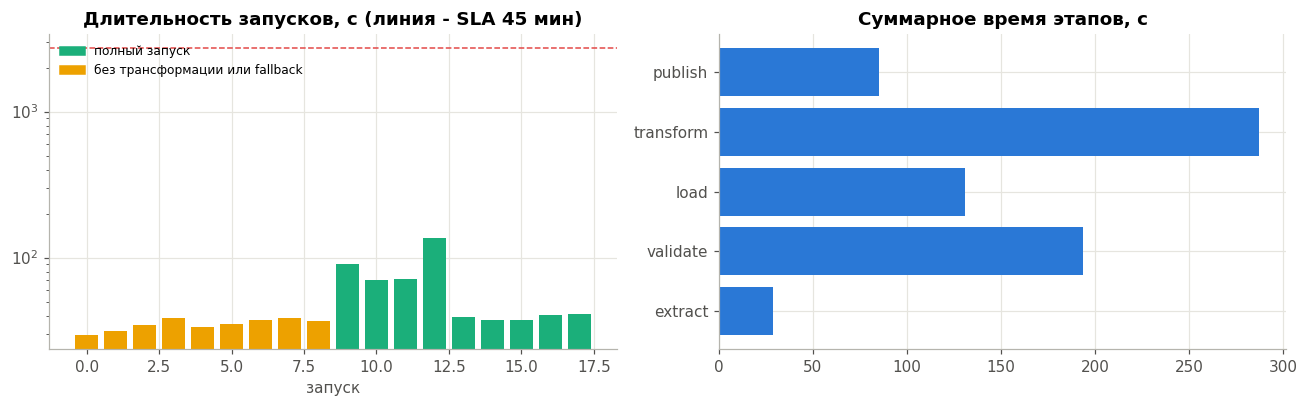

,вызовов,среднее_с,макс_с
stage,,,
extract,295,0.097,0.249
load,295,0.443,1.475
publish,9,9.471,19.849
transform,9,31.947,81.807
validate,295,0.657,1.387


# TYPE pipeline gauge (последние значения по этапам)
pipeline_dbt_nodes{stage="transform"} 32
pipeline_dbt_tests{stage="transform"} 26
pipeline_dlq_inserted{stage="load"} 83
pipeline_duplicates{stage="validate"} 61
pipeline_gx_success_percent{stage="validate"} 100.0
pipeline_inserted{stage="load"} 83357
pipeline_inserted{stage="publish"} 70290
pipeline_raw_version{stage="load"} 295
pipeline_reco_version{stage="publish"} 72
pipeline_rows_dlq{stage="pipeline"} 83
pipeline_rows_dlq{stage="validate"} 83



,level,kind,message
10,warning,sla,запуск занял 21.1 с при SLA 1 с


In [ ]:
m = pd.DataFrame(read_jsonl('work/logs/metrics.jsonl'))
runs = m[m.stage == 'pipeline'].copy()
runs['ts'] = pd.to_datetime(runs['ts'])
stages = m[m.stage.isin(['extract', 'validate', 'load', 'transform', 'publish'])]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(len(runs)), runs.seconds, color=[COLORS['ok'] if s == 'ok' else COLORS['warn'] for s in runs.status])
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=COLORS['ok'], label='полный запуск'), Patch(color=COLORS['warn'], label='без трансформации или fallback')],
             fontsize=8, loc='upper left')
ax[0].axhline(45 * 60, color=COLORS['fail'], ls='--', lw=1)
ax[0].set_yscale('log'); ax[0].set_title('Длительность запусков, с (линия - SLA 45 мин)'); ax[0].set_xlabel('запуск')
agg = stages.groupby('stage').seconds.sum().reindex(['extract', 'validate', 'load', 'transform', 'publish'])
ax[1].barh(agg.index, agg.values, color=COLORS['etl']); ax[1].set_title('Суммарное время этапов, с')
plt.tight_layout(); plt.show()
perf = stages.groupby('stage').agg(вызовов=('seconds', 'size'), среднее_с=('seconds', 'mean'), макс_с=('seconds', 'max'))
display(perf.round(3))
with open('work/logs/metrics.prom') as fh:
    print(''.join(fh.readlines()[:12]))

use_root(SB)
for hr in ('16',):
    shutil.copytree(f'{LANDING}/dt={HISTORY[0]}/hr={hr}', f'{SB}/landing/dt={HISTORY[0]}/hr={hr}', dirs_exist_ok=True)
r9, _ = run(partitions=[f'{HISTORY[0]}/16'], sla_seconds=1)
display(pd.DataFrame(read_jsonl(f'{SB}/logs/alerts.jsonl'))[['level', 'kind', 'message']].tail(1))
_ = use_root('work')

### 4) Проверьте работу оркестратора:

**Запустите пайплайн вручную. Проверьте UI оркестратора.** Запуски выше выполнены вызовом flow из ноутбука, это ручной запуск. Prefect поднимает временный API-сервер и хранит в нём все запуски. Браузерный интерфейс в ноутбуке не открыть, поэтому ниже те же данные, что показывает UI: список запусков из API Prefect и диаграмма Ганта задач последнего ежечасного запуска с подпотоками.

Запусков в API Prefect: 200


запусков
flow             state              
ingest_partition Completed       180
                 Failed            1
reco_etl         Completed        19

Запуск snobbish-robin: Completed, 41.4 с, подпотоков 1


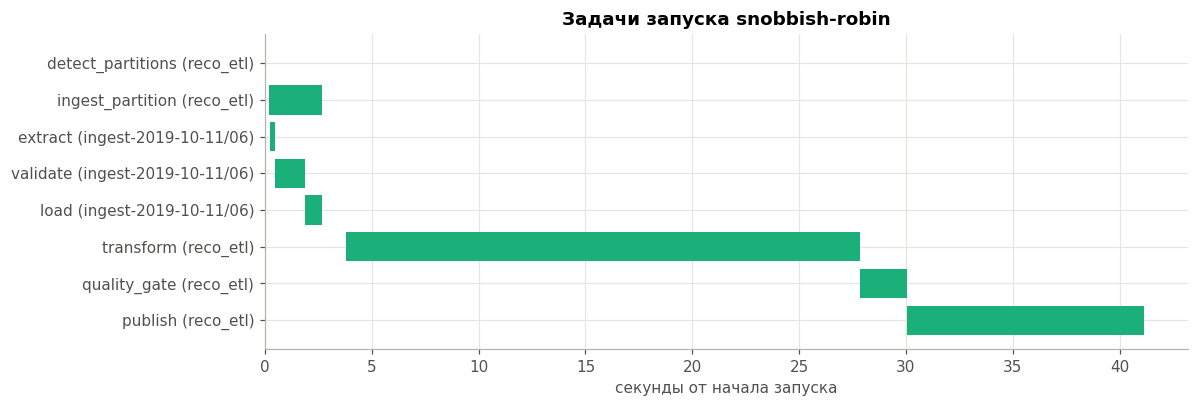

Порядок первых стартов задач: ['detect_partitions', 'ingest_partition', 'extract', 'validate', 'load', 'transform', 'quality_gate', 'publish']


In [ ]:
with get_client(sync_client=True) as c:
    frs = c.read_flow_runs(limit=200)
fr = pd.DataFrame([{'name': f.name, 'flow': 'ingest_partition' if f.parent_task_run_id else 'reco_etl', 'state': f.state_name,
                    'start': f.start_time, 'duration_s': f.total_run_time.total_seconds()} for f in frs])
print('Запусков в API Prefect:', len(fr))
display(fr.groupby(['flow', 'state']).size().rename('запусков').to_frame())

top, subs, tasks = flow_tree(hourly_df.flow_run_id.iloc[-1])
print(f'Запуск {top.name}: {top.state_name}, {top.total_run_time.total_seconds():.1f} с, подпотоков {len(subs)}')
t0 = tasks.start.min()
fig, ax = plt.subplots(figsize=(11, 0.35 * len(tasks) + 1))
for i, r in tasks.iterrows():
    ax.barh(i, (r.end - r.start).total_seconds(), left=(r.start - t0).total_seconds(),
            color=COLORS['ok'] if r.state == 'Completed' else COLORS['fail'])
ax.set_yticks(range(len(tasks)))
ax.set_yticklabels([f"{r.task} ({r.flow_run if r.flow_run != top.name else 'reco_etl'})" for _, r in tasks.iterrows()])
ax.invert_yaxis(); ax.set_xlabel('секунды от начала запуска'); ax.set_title(f'Задачи запуска {top.name}')
plt.tight_layout(); plt.show()
order_ok = tasks.groupby('task').start.min().sort_values().index.tolist()
print('Порядок первых стартов задач:', order_ok)

**Убедитесь, что зависимости обрабатываются корректно.** На диаграмме каждая задача стартует после завершения той, от которой зависит: `detect_partitions`, затем `extract -> validate -> load` внутри подпотока, затем `transform -> quality_gate -> publish`.

**Требования к отчету:**

- **Код оркестрации пайплайна:** `prefect_flows/etl_pipeline.py`.
- **Скриншоты UI оркестратора:** вместо скриншотов - данные API Prefect (список запусков и диаграмма задач), пункт 4.
- **Метрики производительности:** пункт 3. За 295 партиций средние времена этапов: extract 0,10 с, validate 0,66 с, load 0,44 с; transform (dbt) в среднем 31,9 с (максимум 81,8 с) и publish 9,5 с на 9 запусков. Основное время пайплайна уходит на трансформацию и публикацию, загрузка партиции занимает около секунды. Ежечасные запуски на одну партицию длились 38-41 с (первый, на две партиции, 136 с), что намного ниже SLA в 45 минут. Алерт `sla` проверен на песочнице с порогом 1 с: сработал при длительности 21,1 с. В `metrics.prom` метрики доступны для Prometheus.
- **Вывод о преимуществах выбранного оркестратора:** Prefect позволил описать пайплайн обычными функциями Python: retries с экспоненциальной задержкой, подпотоки и динамическое число задач задаются декораторами, без отдельного планировщика и базы метаданных. Для такого объёма это главное преимущество перед Airflow. Цена этого - меньше готовых операторов (dbt и GX вызываются из кода задач). Для ежечасного расписания в production flow разворачивается через `flow.serve(cron='0 * * * *')` или deployment на worker.

## Часть 5: Тестирование данных с Great Expectations

### 1) Установите и настройте Great Expectations:

GX ставится в первом блоке кода. Вместо `great_expectations init` (CLI убран из GX 1.x) контекст создаётся кодом: `gx.get_context(mode='file', project_root_dir='.')` создаёт каталог `gx/` с наборами ожиданий, определениями валидаций, чекпоинтами и Data Docs. Наборы и чекпоинты создаёт `ensure_gx_objects` при каждом запуске пайплайна.

In [ ]:
for root, dirs, files in sorted(os.walk('gx')):
    if 'uncommitted' in root:
        continue
    depth = root.count(os.sep)
    print('  ' * depth + os.path.basename(root) + '/')
    for f in sorted(files)[:6]:
        print('  ' * (depth + 1) + f)

gx/
  .gitignore
  great_expectations.yml
  checkpoints/
    fact_sales_checkpoint.json
    raw_batch_checkpoint.json
    recommendations_checkpoint.json
  expectations/
    .ge_store_backend_id
    fact_sales.json
    raw_batch.json
    recommendations.json
  plugins/
    custom_data_docs/
      renderers/
      styles/
        data_docs_custom_styles.css
      views/
  validation_definitions/
    fact_sales_vd.json
    raw_batch_vd.json
    recommendations_vd.json


### 2) Создайте набор тестов для данных:

Три набора (`suite_definitions` в `pipeline/quality.py`):
- `raw_batch` - пакет перед загрузкой: нет пропусков в критичных полях, тип события из списка, цена в диапазоне (0; 100 000], уникальность `idempotency_key`;
- `recommendations` - витрина после трансформации: ранг 1-10, уникальность пар (пользователь, ранг) и (пользователь, товар), версия модели совпадает с production, товар есть в `dim_products`;
- `fact_sales` - продажи: уникальность `sale_id`, сумма > 0, рубли заполнены, связи с `dim_products` и `dim_users`.

**Проверка связей между таблицами.** В GX 1.x нет готового ожидания для внешнего ключа, поэтому связь вычисляется в DuckDB левым соединением (флаг `product_in_dim`), а GX проверяет, что флаг всегда истинен. В наборе остаётся одно маленькое ожидание, а не список из сотен тысяч идентификаторов.

In [ ]:
ctx = q.gx_context()
rows = []
for s in ctx.suites.all():
    for e in s.expectations:
        kw = {k: v for k, v in e.configuration.kwargs.items() if k not in ('batch_id',)}
        rows.append({'suite': s.name, 'expectation': e.expectation_type, 'kwargs': json.dumps(kw, ensure_ascii=False, default=str)})
display(pd.DataFrame(rows))

,suite,expectation,kwargs
0,raw_batch,expect_column_values_to_not_be_null,"{""column"": ""idempotency_key""}"
1,raw_batch,expect_column_values_to_not_be_null,"{""column"": ""event_time""}"
2,raw_batch,expect_column_values_to_not_be_null,"{""column"": ""event_type""}"
3,raw_batch,expect_column_values_to_not_be_null,"{""column"": ""product_id""}"
4,raw_batch,expect_column_values_to_not_be_null,"{""column"": ""user_id""}"
5,raw_batch,expect_column_values_to_not_be_null,"{""column"": ""price""}"
6,raw_batch,expect_column_values_to_not_be_null,"{""column"": ""user_session""}"
7,raw_batch,expect_column_values_to_be_in_set,"{""column"": ""event_type"", ""value_set"": [""view"", ""cart"", ""purchase"", ""remove_from_cart""]}"
8,raw_batch,expect_column_values_to_be_between,"{""column"": ""price"", ""min_value"": 0.0, ""max_value"": 100000.0, ""strict_min"": true}"
9,raw_batch,expect_column_values_to_be_between,"{""column"": ""user_id"", ""min_value"": 1.0}"


### 3) Интегрируйте тесты в пайплайн:

`validate_task` запускает чекпоинт `raw_batch_checkpoint` на каждой партиции после построчных правил. Если проверка не прошла, вся партиция уходит в DLQ с причиной `gx_failed`, отправляется алерт. `quality_gate_task` запускает `recommendations_checkpoint` и `fact_sales_checkpoint` после dbt; провал вызывает `DataValidationError`, публикация отменяется.

**Примеры проваленных тестов и их обработки.** Набор `raw_batch` запускается на испорченной партиции песочницы без построчных правил, то есть так, как если бы DLQ не было.

In [ ]:
os.environ['LAB3_ROOT'] = os.path.abspath(SB)
bad = ex.extract_partition(SBP, f'{HISTORY[0]}/11').to_pandas()
con = duckdb.connect()
bad_typed = con.execute("""SELECT idempotency_key, TRY_STRPTIME(event_time, '%Y-%m-%d %H:%M:%S UTC') AS event_time, event_type,
                                  TRY_CAST(product_id AS BIGINT) AS product_id, TRY_CAST(user_id AS BIGINT) AS user_id,
                                  TRY_CAST(price AS DOUBLE) AS price, user_session FROM bad""").df()
con.close()
failed_rep = q.run_checkpoint(q.gx_context(), 'raw_batch', bad_typed)
print(f"success={failed_rep['success']}, выполнено {failed_rep['successful']} из {failed_rep['evaluated']} ожиданий "
      f"({failed_rep['success_percent']:.1f}%)")
display(pd.DataFrame(failed_rep['failed']))
_ = use_root('work')

success=False, выполнено 5 из 11 ожиданий (45.5%)


,expectation,column,unexpected_count,unexpected_percent,examples
0,expect_column_values_to_be_unique,idempotency_key,2092,3.151884,"[5fd30dbeb8273f2f5c0931add572b881, 060bfa6a37ef4864bc3739ddc607a601, 2e2f88649a68f3fb483eea98ba0e6f3f, 40948472d995c..."
1,expect_column_values_to_not_be_null,event_time,333,0.501710,"[NaT, NaT, NaT, NaT, NaT]"
2,expect_column_values_to_be_in_set,event_type,333,0.501710,"[click, click, click, click, click]"
3,expect_column_values_to_not_be_null,user_id,333,0.501710,"[<NA>, <NA>, <NA>, <NA>, <NA>]"
4,expect_column_values_to_not_be_null,price,333,0.501710,"[nan, nan, nan, nan, nan]"
5,expect_column_values_to_be_between,price,776,1.175045,"[0.0, 0.0, 0.0, 0.0, 0.0]"


Провалены ожидания на пропуски (`event_time`, `user_id`, `price`), тип события, диапазон цены и уникальность ключа: у части испорченных строк изменена только цена, и ключ совпадает с исходным событием той же партиции. Все провалы соответствуют испорченным строкам. В пайплайне эти строки отсекаются правилами DLQ раньше, и `raw_batch` на оставшихся проходит на 100%. Если бы правила что-то пропустили, партиция ушла бы в DLQ целиком (`gx_failed`).

### 4) Настройте регулярное выполнение тестов:

- **Перед загрузкой данных:** `raw_batch` в `validate_task` для каждой партиции каждого запуска.
- **После трансформации:** `recommendations` и `fact_sales` в `quality_gate_task`.
- **В оркестраторе как отдельная задача:** `quality_gate` - отдельная задача flow между `transform` и `publish` (видна на диаграмме в Части 4); в CI тот же чекпоинт запускает `python -m pipeline.ci gx`.

Результаты всех проверок основного хранилища за все запуски:

In [ ]:
m = pd.DataFrame(read_jsonl('work/logs/metrics.jsonl'))
gx_raw = m[m.stage == 'validate'].gx_success_percent.dropna()
gx_marts = m[m.stage.str.startswith('gx_')]
gx_stats = pd.DataFrame([
    {'набор': 'raw_batch', 'проверок': len(gx_raw), 'средний % успеха': gx_raw.mean(), 'провалов': int((gx_raw < 100).sum())},
    *[{'набор': s[3:], 'проверок': len(g), 'средний % успеха': g.success_percent.mean(), 'провалов': int((g.success == 0).sum())}
      for s, g in gx_marts.groupby('stage')]])
display(gx_stats.round(2))
DATA_QUALITY_SCORE = float(pd.concat([gx_raw, gx_marts.success_percent]).mean())

,набор,проверок,средний % успеха,провалов
0,raw_batch,295,100.0,0
1,fact_sales,9,100.0,0
2,recommendations,9,100.0,0


**Отчеты визуализации тестов (HTML).** Чекпоинты витрин обновляют Data Docs (`gx/uncommitted/data_docs/local_site/index.html`, страница на каждую валидацию; проверка партиций Data Docs не трогает, иначе сайт пересобирался бы на каждый час). Data Docs подключают стили по относительным путям, поэтому в ноутбуке страница выводится не целиком: ниже число сформированных страниц и сводный HTML-отчёт по последним валидациям каждого набора, собранный из тех же результатов.

In [ ]:
pages = glob.glob('gx/uncommitted/data_docs/local_site/validations/**/*.html', recursive=True)
print(f'Data Docs: {len(pages)} страниц валидаций, индекс gx/uncommitted/data_docs/local_site/index.html')
res_files = sorted(glob.glob('gx/uncommitted/validations/**/*.json', recursive=True), key=os.path.getmtime)
latest = {}
for f in res_files:
    d = json.load(open(f))
    latest[d.get('suite_name') or d.get('meta', {}).get('expectation_suite_name')] = d
html = ['<table style="border-collapse:collapse;font-size:12px">',
        '<tr><th style="text-align:left;padding:3px 8px">Набор</th><th style="text-align:left;padding:3px 8px">Ожидание</th>'
        '<th style="text-align:left;padding:3px 8px">Колонка</th><th style="padding:3px 8px">Результат</th>'
        '<th style="padding:3px 8px">Нарушений</th></tr>']
for suite, d in latest.items():
    for r in d['results']:
        cfg = r['expectation_config']
        ok = r['success']
        html.append(f"<tr><td style='padding:3px 8px'>{suite}</td><td style='padding:3px 8px'>{cfg.get('type') or cfg.get('expectation_type')}</td>"
                    f"<td style='padding:3px 8px'>{cfg['kwargs'].get('column') or cfg['kwargs'].get('column_list') or ''}</td>"
                    f"<td style='padding:3px 8px;color:{'#1baf7a' if ok else '#e34948'}'>{'pass' if ok else 'FAIL'}</td>"
                    f"<td style='padding:3px 8px;text-align:right'>{r['result'].get('unexpected_count', '')}</td></tr>")
html.append('</table>')
with open('work/gx_report.html', 'w') as fh:
    fh.write('<html><meta charset="utf-8"><body>' + ''.join(html) + '</body></html>')
display(HTML(''.join(html)))

Data Docs: 36 страниц валидаций, индекс gx/uncommitted/data_docs/local_site/index.html


Набор,Ожидание,Колонка,Результат,Нарушений
raw_batch,expect_column_values_to_not_be_null,idempotency_key,pass,0
raw_batch,expect_column_values_to_be_unique,idempotency_key,FAIL,2092
raw_batch,expect_column_values_to_not_be_null,event_time,FAIL,333
raw_batch,expect_column_values_to_not_be_null,event_type,pass,0
raw_batch,expect_column_values_to_be_in_set,event_type,FAIL,333
raw_batch,expect_column_values_to_not_be_null,product_id,pass,0
raw_batch,expect_column_values_to_not_be_null,user_id,FAIL,333
raw_batch,expect_column_values_to_be_between,user_id,pass,0
raw_batch,expect_column_values_to_not_be_null,price,FAIL,333
raw_batch,expect_column_values_to_be_between,price,FAIL,776


**Требования к отчету:**

- **Конфигурация тестов Great Expectations:** пункт 2 (таблица ожиданий трёх наборов, JSON в `gx/expectations/`).
- **Примеры проваленных тестов и их обработки:** пункт 3.
- **Интеграция тестов в пайплайн:** пункты 3 и 4.
- **Отчеты визуализации тестов (HTML):** Data Docs в `gx/uncommitted/data_docs/` и сводный отчёт `work/gx_report.html` (пункт 4).

## Часть 6: DBT для трансформаций (ELT)

### 1) Установите и настройте DBT:

Ставится адаптер `dbt-duckdb` (вместо `dbt-spark`: хранилище здесь DuckDB). Проект создан файлами, а не интерактивным `dbt init`: `dbt_project.yml` и `profiles.yml` записаны выше. Профиль берёт путь к базе, путь к Delta-таблице и лимит памяти DuckDB из переменных окружения, которые задаёт пайплайн. DuckDB читает Delta расширением `delta` (`delta_scan`).

In [ ]:
v = subprocess.run([sys.executable, '-m', 'dbt.cli.main', '--version'], capture_output=True, text=True)
print(v.stdout.strip()[:400])
dbg = tr.run_dbt(PATHS, ['debug'], check=False)
print('\n'.join(l for l in dbg['log'].splitlines() if 'OK' in l or 'ERROR' in l or 'All checks' in l)[-800:])

Core:
  - installed: 1.12.6
  - latest:    1.12.6 - Up to date!

Plugins:
  - duckdb: 1.11.1 - Up to date!


16:20:07  dbt v2 is available, and is the default for new installations. This is dbt Core v1.
          New project - install v2: https://docs.getdbt.com/docs/local/install-dbt?utm_source=dbt-cli
          Existing v1 project - upgrade guide: https://docs.getdbt.com/docs/dbt-versions/db
16:20:13    profiles.yml file [OK found and valid]
16:20:13    dbt_project.yml file [OK found and valid]
16:20:13   - git [OK found]
16:20:13    Connection test: [OK connection ok]
16:20:13  All checks passed!


### 2) Создайте структуру проекта DBT:

In [ ]:
for root, dirs, files in os.walk('dbt_reco'):
    dirs[:] = sorted(d for d in dirs if d not in ('target', 'logs', 'dbt_packages'))
    depth = root.count(os.sep)
    print('  ' * depth + os.path.basename(root) + '/')
    for f in sorted(files):
        print('  ' * (depth + 1) + f)

dbt_reco/
  dbt_project.yml
  profiles.yml
  macros/
    category_level.sql
    event_weight.sql
    usd_to_rub.sql
  models/
    marts/
      schema.yml
      core/
        dim_products.sql
        dim_users.sql
        fact_sales.sql
      reco/
        item_popularity.sql
        user_recommendations.sql
    staging/
      events/
        schema.yml
        sources.yml
        stg_events.sql
  tests/
    assert_no_bought_recommended.sql
    assert_recommendations_unique.sql
    assert_sales_amount_not_null.sql
    generic/
      positive.sql
      value_between.sql


### 3) Реализуйте трансформации:

- **Staging-модели для очистки данных:** `stg_events` - фильтр `price > 0`, `unknown` вместо пустых `brand` и `category_code`, бренд в нижнем регистре, уровень категории `category_l1`; инкрементальная по `idempotency_key`.
- **Marts-модели для бизнес-логики:** `core`: `fact_sales`, `dim_users`, `dim_products`; `reco`: `item_popularity` (популярность товара в категории за окно 10 дней) и `user_recommendations` (топ-10 категории интереса без уже купленного, добор из глобального топа).
- **Макросы для повторяющихся операций:** `usd_to_rub` (пересчёт денег по курсу, аналог `calculate_tax`), `event_weight` (вес действия), `category_level` (уровень иерархии категории).

Размеры моделей в основном хранилище и пример рекомендаций:

In [ ]:
con = duckdb.connect(PATHS.warehouse, read_only=True)
sizes = pd.DataFrame([(t, con.execute(f'SELECT count(*) FROM {t}').fetchone()[0])
                      for t in ('stg_events', 'fact_sales', 'dim_users', 'dim_products', 'item_popularity', 'user_recommendations')],
                     columns=['модель', 'строк'])
display(sizes)
display(con.execute("""SELECT r.user_id, r.rank, r.product_id, p.category_code, p.brand, round(p.last_price_usd, 2) AS price_usd,
                              r.score, r.source, r.model_version
                       FROM user_recommendations r JOIN dim_products p USING (product_id)
                       WHERE r.user_id = (SELECT min(user_id) FROM user_recommendations) ORDER BY rank""").df())
src_share = con.execute("SELECT source, count(*) * 100.0 / sum(count(*)) OVER () AS pct FROM user_recommendations GROUP BY 1").df()
con.close()
display(src_share.round(2))

,модель,строк
0,stg_events,13157231
1,fact_sales,227260
2,dim_users,1333610
3,dim_products,128688
4,item_popularity,128263
5,user_recommendations,186970


,user_id,rank,product_id,category_code,brand,price_usd,score,source,model_version
0,382593038,1,12703015,unknown,cordiant,42.99,444.0,category,1.0
1,382593038,2,12703498,unknown,cordiant,40.41,224.0,category,1.0
2,382593038,3,12703494,unknown,cordiant,41.19,196.0,category,1.0
3,382593038,4,12702958,unknown,cordiant,42.47,161.0,category,1.0
4,382593038,5,12703415,unknown,cordiant,48.91,157.0,category,1.0
5,382593038,6,12711986,unknown,triangle,38.35,127.0,category,1.0
6,382593038,7,12711175,unknown,triangle,38.10,120.0,category,1.0
7,382593038,8,12718062,unknown,unknown,32.43,108.0,category,1.0
8,382593038,9,12706259,unknown,nokian,53.54,105.0,category,1.0
9,382593038,10,12718063,unknown,unknown,34.75,103.0,category,1.0


,source,pct
0,category,99.9
1,global,0.1


### 4) Добавьте тесты данных:

Тесты описаны в `schema.yml` (unique, not_null, accepted_values, relationships, свои generic-тесты `positive` и `value_between`) и в каталоге `tests/` (singular-тесты: уникальность списка пользователя, отсутствие купленного в рекомендациях, заполненность суммы в рублях). `dbt build` выполняет тесты сразу после построения модели, и при провале зависимые модели не строятся. Повторное построение основного хранилища на последнем пакете (идемпотентно, результат тот же):

In [ ]:
use_root('work')
lb = ci.last_batch(PATHS)
build = tr.run_dbt(PATHS, ['build'], tr.model_vars(PATHS, lb['as_of'], lb['batch_start']))
dbt_res = pd.DataFrame([{'узел': r['node'].split('.')[-1] if r['node'].startswith('model') else r['node'].split('.')[2],
                         'тип': r['node'].split('.')[0], 'статус': r['status'], 'нарушений': r['failures'],
                         'с': r['seconds']} for r in build['results']])
print(dbt_res.groupby(['тип', 'статус']).size().to_dict())
display(dbt_res)

{('model', 'success'): 6, ('test', 'pass'): 26}


,узел,тип,статус,нарушений,с
0,stg_events,model,success,NaN,2.49
1,not_null_stg_events_idempotency_key,test,pass,0.0,0.08
2,not_null_stg_events_product_id,test,pass,0.0,0.03
3,not_null_stg_events_user_id,test,pass,0.0,0.03
4,positive_stg_events_price,test,pass,0.0,0.06
5,accepted_values_stg_events_event_type__view__cart__purchase__remove_from_cart,test,pass,0.0,0.41
6,unique_stg_events_idempotency_key,test,pass,0.0,3.78
7,dim_products,model,success,NaN,2.52
8,fact_sales,model,success,NaN,1.47
9,dim_users,model,success,NaN,4.55


### 5) Интегрируйте DBT в оркестратор:

Аналог `DbtRunOperator` - задача `transform_task`: вызывает `dbt build` с переменными пакета (`as_of`, `batch_start`, параметры production-модели) в отдельном процессе, потому что файл DuckDB может держать открытым только один процесс-писатель. Результаты узлов берутся из `run_results.json` и пишутся в метрики.

**Скриншоты DBT Docs (граф зависимостей).** `dbt docs generate` строит `manifest.json` и `catalog.json`, из них же строится страница DBT Docs. Граф зависимостей ниже нарисован из `manifest.json`.

dbt docs generate: ok | файлы: ['manifest.json', 'catalog.json', 'index.html']


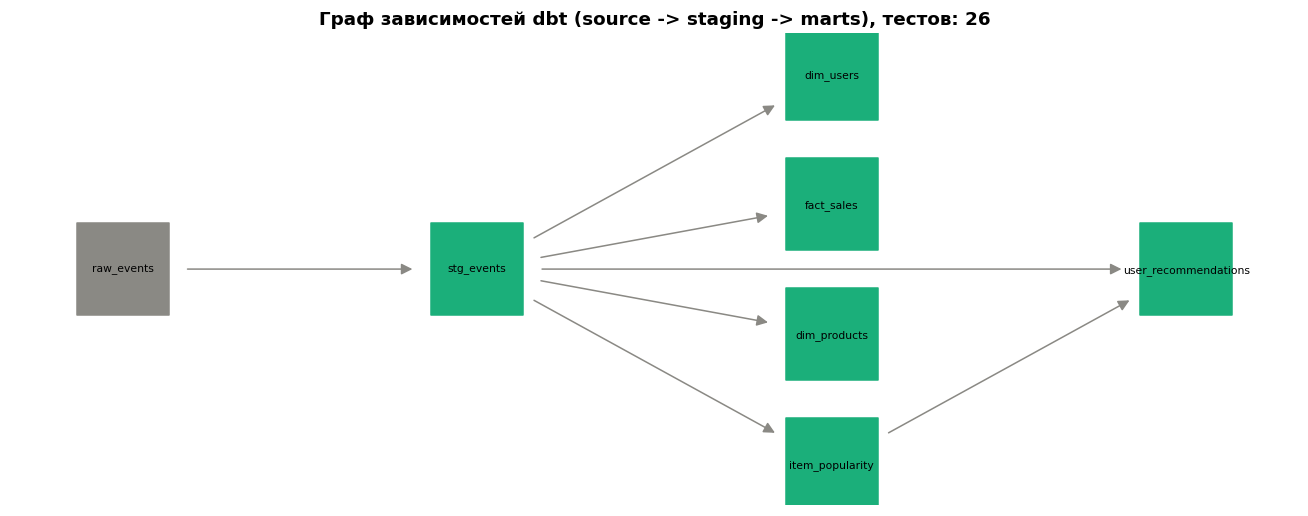

In [ ]:
gen = tr.run_dbt(PATHS, ['docs', 'generate'], tr.model_vars(PATHS, lb['as_of'], lb['batch_start']), check=False)
print('dbt docs generate:', 'ok' if gen['returncode'] == 0 else gen['log'][-500:],
      '| файлы:', [f for f in ('manifest.json', 'catalog.json', 'index.html') if os.path.exists(f'dbt_reco/target/{f}')])
man = json.load(open('dbt_reco/target/manifest.json'))
G = nx.DiGraph()
for uid, node in {**man['nodes'], **man['sources']}.items():
    if node['resource_type'] in ('model', 'source'):
        G.add_node(uid.split('.')[-1], kind=node['resource_type'])
for uid, node in man['nodes'].items():
    if node['resource_type'] == 'model':
        for dep in node['depends_on']['nodes']:
            G.add_edge(dep.split('.')[-1], uid.split('.')[-1])
n_tests = sum(n['resource_type'] == 'test' for n in man['nodes'].values())
layers = {n: (0 if G.nodes[n]['kind'] == 'source' else 1 if n.startswith('stg') else 2 if n in ('fact_sales', 'dim_users', 'dim_products', 'item_popularity') else 3) for n in G}
for n, l in layers.items():
    G.nodes[n]['layer'] = l
pos = nx.multipartite_layout(G, subset_key='layer')
fig, ax = plt.subplots(figsize=(12, 4.8))
nx.draw_networkx(G, pos, ax=ax, node_color=[COLORS['grey'] if G.nodes[n]['kind'] == 'source' else COLORS['elt'] for n in G],
                 node_size=3600, font_size=7, arrowsize=15, edge_color='#8a8984', node_shape='s')
ax.set_title(f'Граф зависимостей dbt (source -> staging -> marts), тестов: {n_tests}'); ax.axis('off')
plt.tight_layout(); plt.show()

**Требования к отчету:**

- **Структура DBT-проекта:** пункт 2.
- **Примеры SQL-моделей:** файлы `dbt_reco/models/` (записаны в разделе «Код пайплайна»), пример результата в пункте 3.
- **Тесты данных и их результаты:** пункт 4: все тесты последнего построения прошли. Пример провала теста - в Части 7 (версия модели, которая рекомендует уже купленное).
- **Скриншоты DBT Docs (граф зависимостей):** граф из `manifest.json` в пункте 5.

## Часть 7: Интеграция в CI/CD

### 1) Настройте GitHub Actions для CI/CD:

Конфигурация `.github/workflows/ci.yml` записана выше. Три задания:
- `test` - на каждый pull request и push: pytest (идемпотентность и DLQ на тестовых данных), прогон пайплайна на тестовых данных, чекпоинт GX и `dbt test` по его результату;
- `deploy-staging` - только для `main` после `test`: сборка новой версии модели в staging и smoke-тест;
- `deploy-production` - окружение `production` с обязательным одобрением ревьюера: canary на 5% пользователей, продвижение, при провале автоматический откат.

Шаги вызывают команды `python -m pipeline.ci <команда>`. Ниже задание `test` выполняется теми же командами.

In [ ]:
def job(name, cmd, env=None):
    t = time.perf_counter()
    p = subprocess.run(cmd, capture_output=True, text=True, env={**os.environ, **(env or {})})
    out = p.stdout.strip()
    try:
        j = json.loads(out[out.index('{'):])
        summary = ', '.join(f'{k}={j[k]}' for k in ('status', 'success', 'success_percent', 'returncode', 'rows_in', 'failed')
                            if k in j)
    except ValueError:
        summary = next((l for l in out.splitlines()[::-1] if 'passed' in l or 'failed' in l), out[-110:])
    return {'шаг': name, 'код': p.returncode, 'результат': 'success' if p.returncode == 0 else 'failure',
            'с': round(time.perf_counter() - t, 1), 'вывод': summary[:110]}

shutil.rmtree('work/ci_run', ignore_errors=True)
ci_steps = [
    job('Pipeline tests (idempotency, DLQ)', [sys.executable, '-m', 'pytest', '-q', '--color=no', 'tests', '-p', 'no:cacheprovider'],
        {'PREFECT_HOME': os.path.abspath('work/.prefect_ci'), 'PREFECT_LOGGING_LEVEL': 'ERROR'}),
    job('Run pipeline on sample data', [sys.executable, '-m', 'pipeline.ci', 'sample-run', '--root', 'work/ci_run'],
        {'PREFECT_HOME': os.path.abspath('work/.prefect_ci'), 'PREFECT_LOGGING_LEVEL': 'ERROR'}),
    job('Run Great Expectations', [sys.executable, '-m', 'pipeline.ci', 'gx', '--root', 'work/ci_run']),
    job('Test DBT models', [sys.executable, '-m', 'pipeline.ci', 'dbt-test', '--root', 'work/ci_run']),
]
shutil.rmtree('work/ci_run', ignore_errors=True)
display(pd.DataFrame(ci_steps))

,шаг,код,результат,с,вывод
0,"Pipeline tests (idempotency, DLQ)",0,success,59.5,2 passed in 52.02s
1,Run pipeline on sample data,0,success,33.1,"status=ok, rows_in=6000"
2,Run Great Expectations,0,success,7.6,"success=True, success_percent=100.0, failed=[]"
3,Test DBT models,0,success,7.5,"returncode=0, failed=[]"


### 2) Реализуйте безопасный деплой:

Новая версия модели 1.1: окно популярности 7 дней вместо 10, добавления в корзину учитываются с весом 0,3. Путь до production:
1. `deploy-staging`: dbt build версии в отдельную базу `staging.duckdb` (на тех же сырых данных) со всеми тестами;
2. smoke-тест (`smoke_test.py`): рекомендации есть, у 99% пользователей полный список из 10 товаров, поиск списка по `user_id` укладывается в 100 мс (требование сценария к инференсу);
3. **canary release:** версия обслуживает 5% пользователей (`user_id % 100 < 5`). На них сравнивается HitRate@10 текущей и новой версии: доля пользователей, которые в следующие 24 часа взаимодействовали хотя бы с одним рекомендованным товаром (данные следующего дня есть в landing). Новая версия продвигается, если она не хуже;
4. продвижение: реестр `production_model.json` получает новую версию, следующий ежечасный запуск публикует её рекомендации;
5. автоматический откат: прежняя версия в реестре и `restore` таблицы сервинга на версию до продвижения.

In [ ]:
use_root('work')
lb = ci.last_batch(PATHS)
prod_model = tr.production_model(PATHS)
cand_ok = {**prod_model, 'model_version': '1.1', 'window_days': 7, 'cart_weight': 0.3}
cand_bad = {**prod_model, 'model_version': '1.2', 'exclude_bought': False}
STAGING = PATHS.p('staging.duckdb')
deploy_log, profiles = [], {}


def reco_profile(wh, as_of):
    hr = deploy.hit_rate(PATHS.landing, wh, as_of)
    con = duckdb.connect(wh, read_only=True)
    share = con.execute("SELECT avg((source = 'category')::INT) FROM user_recommendations").fetchone()
    con.close()
    return {'пользователей': hr['users'], 'HitRate@10 (любое событие)': hr['hit_rate_any'],
            'HitRate@10 (покупка)': hr['hit_rate_purchase'], 'доля из категории интереса': share[0]}


def pipeline_for(candidate):
    """Задания deploy-staging и deploy-production для одной версии модели."""
    out = {'версия': candidate['model_version']}
    if os.path.exists(STAGING):
        os.remove(STAGING)
    b = deploy.build_version(PATHS, candidate, STAGING, lb['as_of'], lb['batch_start'])
    out['staging: dbt build'] = 'success' if b['ok'] else 'failure: ' + ', '.join(
        f"{f['node'].split('.')[2]} ({f['failures']})" for f in b['failed'])
    if not b['ok']:
        out['итог'] = 'деплой остановлен, production не изменён'
        return out, None
    smoke = deploy.smoke_test(STAGING, k=candidate['k'])
    out['smoke'] = f"{'success' if smoke['passed'] else 'failure'}: полных списков {smoke['full_list_share']:.1%}, p99 поиска {smoke['lookup_p99_ms']:.2f} мс"
    if not smoke['passed']:
        out['итог'] = 'деплой остановлен'
        return out, None
    can = deploy.canary(PATHS, PATHS.warehouse, STAGING, lb['as_of'], share=5)
    out['canary 5%'] = (f"HitRate@10 {can['production']['hit_rate_any']:.4f} -> {can['candidate']['hit_rate_any']:.4f} "
                        f"на {can['candidate']['users']} польз.")
    out['итог'] = 'canary пройден, ждёт продвижения' if can['promote'] else 'canary хуже, откат: production не изменён'
    profiles[f"{prod_model['model_version']} (production)"] = reco_profile(PATHS.warehouse, lb['as_of'])
    profiles[f"{candidate['model_version']} (новая)"] = reco_profile(STAGING, lb['as_of'])
    return out, can

res_bad, _ = pipeline_for(cand_bad)
res_ok, can_ok = pipeline_for(cand_ok)
deploy_log += [res_bad, res_ok]
display(pd.DataFrame(deploy_log).fillna(''))

,версия,staging: dbt build,итог,smoke,canary 5%
0,1.2,failure: assert_no_bought_recommended (2508),"деплой остановлен, production не изменён",,
1,1.1,success,"canary пройден, ждёт продвижения","success: полных списков 100.0%, p99 поиска 2.63 мс",HitRate@10 0.1000 -> 0.1044 на 910 польз.


Версия 1.2 (рекомендует уже купленное) не прошла dbt-тест `assert_no_bought_recommended` ещё в staging, это пример проваленного деплоя: production не изменился. Решение по версии 1.1 принимается по canary.

In [ ]:
reco_before = st.table_version(PATHS.reco)
if can_ok['promote']:
    deploy.promote(PATHS, cand_ok, 'canary: HitRate@10 не хуже текущей версии')
# первый ежечасный запуск после деплоя публикует рекомендации новой версии
res_after, _ = run(until=f'{HOURLY_DAY}/{HOURLY_RUNS + 2:02d}')
print('Запуск после деплоя:', {k: res_after.get(k) for k in ('status', 'partitions', 'reco_version')},
      '| модель в production:', tr.production_model(PATHS)['model_version'])

# автоматический откат: после деплоя проверка на production не прошла (имитация: порог задержки 0,001 мс)
post_smoke = deploy.smoke_test(PATHS.warehouse, latency_ms=0.001)
rollback = deploy.rollback(PATHS, f"smoke после деплоя не прошёл: p99 {post_smoke['lookup_p99_ms']:.2f} мс") if not post_smoke['passed'] else None
print('Откат:', rollback)
print('Модель в production после отката:', tr.production_model(PATHS)['model_version'],
      f'| версия сервинга {st.table_version(PATHS.reco)} (новый коммит RESTORE с содержимым версии {reco_before}, бывшей до деплоя)')
hist_m = pd.DataFrame(deploy.model_history(PATHS))
hist_m['version'] = hist_m.model.map(lambda m: m['model_version'])
display(hist_m[['ts', 'action', 'version', 'reason']])

Запуск после деплоя: {'status': 'ok', 'partitions': ['2019-10-11/07'], 'reco_version': 80} | модель в production: 1.1
Откат: {'model': {'model_name': 'popular_in_category', 'model_version': '1.0', 'k': 10, 'window_days': 10, 'cart_weight': 0, 'exclude_bought': True}, 'reco_restored_to': 72}
Модель в production после отката: 1.0 | версия сервинга 81 (новый коммит RESTORE с содержимым версии 72, бывшей до деплоя)


,ts,action,version,reason
0,2026-11-10T16:23:56+00:00,promote,1.1,canary: HitRate@10 не хуже текущей версии
1,2026-11-10T16:24:35+00:00,rollback,1.0,smoke после деплоя не прошёл: p99 1.20 мс


**Canary release, smoke tests, автоматический откат.** Версия, прошедшая canary, продвигается в реестр, и следующий ежечасный запуск публикует её рекомендации. Затем проверка на production намеренно проваливается (порог задержки 0,001 мс вместо 100 мс), чтобы показать откат: реестр возвращается на прежнюю версию модели, таблица сервинга восстанавливается `restore` на версию до деплоя, история деплоев сохраняется в `model_history.json`.

**Вывод:** версия 1.1 прошла staging, smoke-тест (100% полных списков, p99 поиска 2,63 мс) и canary (HitRate@10 0,1000 -> 0,1044 на 910 пользователях), после чего была продвинута, а следующий ежечасный запуск опубликовал её рекомендации (статус `ok`, версия сервинга 80). Намеренно проваленная проверка на production (p99 1,20 мс при пороге 0,001 мс) вызвала откат: в реестре снова модель 1.0, сервинг восстановлен до содержимого версии 72 новым коммитом (версия 81), оба события записаны в историю деплоев. Версия 1.2 остановлена ещё в staging тестом `assert_no_bought_recommended` (2 508 нарушений), production при этом не изменился. Безопасный деплой работает на всех трёх уровнях: тесты, canary и автоматический откат.

### 3) Добавьте мониторинг после деплоя:

- **Сравнение метрик до и после:** текущая и новая версия модели на одном и том же пакете (все пользователи пакета, а не только canary): HitRate@10 по любому событию и по покупке в следующие 24 часа, доля рекомендаций из категории интереса. Score у версий считается по-разному (у 1.1 в нём есть корзины), поэтому его средние не сравниваются.
- **Отслеживание data drift:** PSI (population stability index) распределений типа события и верхнего уровня категории: эталон - последний день истории, текущее - часы ежечасных запусков. Порог 0,2: выше распределение считается сдвинутым.
- **Логирование бизнес-метрик:** выручка, число покупок и средний чек по часам из `fact_sales` пишутся в `metrics.jsonl` (этап `business`).

In [ ]:
cmp_v = pd.DataFrame(profiles)
display(cmp_v.round(4))

def psi(ref, cur):
    idx = ref.index.union(cur.index)
    r = ref.reindex(idx, fill_value=0) / ref.sum() + 1e-6
    c = cur.reindex(idx, fill_value=0) / cur.sum() + 1e-6
    return float(((c - r) * np.log(c / r)).sum())

con = duckdb.connect()
con.execute('INSTALL delta; LOAD delta')
dist = con.execute(f"""
    SELECT CASE WHEN event_date = DATE '{HOURLY_DAY}' THEN 'current' ELSE 'reference' END AS period, event_type,
           coalesce(nullif(split_part(category_code, '.', 1), ''), 'unknown') AS cat, count(*) AS n
    FROM delta_scan('{PATHS.raw}')
    WHERE event_date IN (DATE '{HISTORY[-1]}', DATE '{HOURLY_DAY}')
    GROUP BY ALL""").df()
con.close()
drift = []
for col in ('event_type', 'cat'):
    g = dist.groupby(['period', col]).n.sum().unstack(0).fillna(0)
    drift.append({'признак': col, 'PSI': psi(g['reference'], g['current']), 'порог': 0.2})
drift_df = pd.DataFrame(drift)
drift_df['drift'] = drift_df.PSI > drift_df['порог']
display(drift_df.round(4))
DATA_DRIFT_PSI = float(drift_df.PSI.max())

con = duckdb.connect(PATHS.warehouse, read_only=True)
biz = con.execute(f"""SELECT date_trunc('hour', event_time) AS hour, count(*) AS purchases, sum(amount_usd) AS revenue_usd,
                             sum(amount_usd) / count(DISTINCT user_id) AS revenue_per_buyer
                      FROM fact_sales WHERE event_date = DATE '{HOURLY_DAY}' GROUP BY 1 ORDER BY 1""").df()
con.close()
for _, r in biz.iterrows():
    common.log_metric(PATHS, 'monitoring', 'business', hour=str(r.hour), purchases=int(r.purchases),
                      revenue_usd=round(float(r.revenue_usd), 2), revenue_per_buyer=round(float(r.revenue_per_buyer), 2))
display(biz.round(2))

,1.0 (production),1.1 (новая)
пользователей,18697.0000,18697.0000
HitRate@10 (любое событие),0.1019,0.1018
HitRate@10 (покупка),0.0124,0.0125
доля из категории интереса,0.9990,0.9990


,признак,PSI,порог,drift
0,event_type,0.0013,0.2,False
1,cat,0.0025,0.2,False


,hour,purchases,revenue_usd,revenue_per_buyer
0,2019-10-11 00:00:00,141,44266.50,406.11
1,2019-10-11 01:00:00,277,71083.70,318.76
2,2019-10-11 02:00:00,559,155206.70,326.75
3,2019-10-11 03:00:00,1133,335169.56,359.62
4,2019-10-11 04:00:00,1535,442575.63,357.20
5,2019-10-11 05:00:00,1826,519562.87,347.53
6,2019-10-11 06:00:00,1872,525803.97,340.11
7,2019-10-11 07:00:00,1871,530438.43,350.12


### 4) Проверьте работу CI/CD:

- **Создайте pull request с изменениями:** workflow запускается событием `pull_request`. Сам PR в ноутбуке не создать, поэтому шаги заданий выполнены командами `pipeline.ci` (пункты 1-2).
- **Убедитесь, что запускаются тесты:** пункт 1, шаги задания `test`.
- **Проверьте деплой в staging:** пункт 2: версия 1.2 остановлена на тестах staging, версия 1.1 прошла staging и smoke.
- **Убедитесь, что production-деплой происходит только после ревью:** задание `deploy-production` привязано к окружению `production`; в настройках репозитория у него включено правило *Required reviewers*, и GitHub ждёт одобрения перед запуском задания. В ноутбуке этот шаг соответствует явному вызову `deploy.promote`.

**Требования к отчету:**

- **Конфигурация CI/CD:** `.github/workflows/ci.yml`, пункт 1.
- **Примеры успешного и проваленного деплоя:** пункт 2 (1.1 прошла, 1.2 остановлена тестами) и откат после деплоя.
- **Стратегия безопасного деплоя:** staging -> smoke -> canary 5% -> ревью -> production, автоматический откат через реестр и Delta restore.
- **Метрики для сравнения версий:** пункт 3. На всех пользователях пакета (18 697) версии 1.0 и 1.1 практически не отличаются: HitRate@10 по любому событию 0,1019 и 0,1018, по покупке 0,0124 и 0,0125, доля рекомендаций из категории интереса 0,999 у обеих. Небольшой выигрыш 1.1 на canary (910 пользователей) на полной выборке не подтвердился, поэтому он лежит в пределах шума. Data drift не обнаружен: PSI по типу события 0,0013 и по категории 0,0025, порог 0,2. Бизнес-метрики по часам (покупки, выручка, выручка на покупателя) записаны в `metrics.jsonl`.

## Автоматические проверки

In [ ]:
SBC = 'work/sandbox_checks'
shutil.rmtree(SBC, ignore_errors=True)
for h in ('10', '11'):
    shutil.copytree(f'{LANDING}/dt={HISTORY[0]}/hr={h}', f'{SBC}/landing/dt={HISTORY[0]}/hr={h}')
P = use_root(SBC)

def run_pipeline():
    return run(partitions=[f'{HISTORY[0]}/10', f'{HISTORY[0]}/11'])[0]

def get_row_count():
    return raw_counts(P)['raw_events']['rows']

def get_dlq_count():
    return raw_counts(P).get('dlq', {'rows': 0})['rows']

def corrupt_data_and_run():
    con = duckdb.connect()
    src = f'{SBC}/landing/dt={HISTORY[0]}/hr=11'
    con.execute(f"COPY (SELECT * REPLACE ('-1' AS price) FROM read_parquet('{src}/*.parquet', hive_partitioning=false) LIMIT 50) "
                f"TO '{src}/corrupted.parquet' (FORMAT parquet)")
    con.close()
    return run(partitions=[f'{HISTORY[0]}/11'], transform=False)[0]

# Проверка 1: Пайплайн должен быть идемпотентным
t0 = time.perf_counter()
run_pipeline()
pipeline_duration = time.perf_counter() - t0
initial_count = get_row_count()
dlq_before = get_dlq_count()
run_pipeline()
assert get_row_count() == initial_count, 'Пайплайн не идемпотентен'
idempotency_passed = IDEMPOTENCY_TEST_PASSED and get_row_count() == initial_count

# Проверка 2: DLQ должен работать
corrupt_data_and_run()
assert get_dlq_count() > dlq_before, 'DLQ не заполняется'
use_root('work')
dlq_error_count = raw_counts(PATHS)['dlq']['rows']
data_quality_score = DATA_QUALITY_SCORE

print(f"## METRICS ##")
print(f"IDEMPOTENCY_TEST_PASSED={idempotency_passed}")
print(f"DLQ_ERROR_COUNT={dlq_error_count}")
print(f"DATA_QUALITY_SCORE={data_quality_score:.2f}")
print(f"PIPELINE_DURATION_SEC={pipeline_duration:.2f}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## METRICS ##
IDEMPOTENCY_TEST_PASSED=True
DLQ_ERROR_COUNT=24809
DATA_QUALITY_SCORE=100.00
PIPELINE_DURATION_SEC=19.50


`DLQ_ERROR_COUNT` - записи DLQ основного хранилища (реальные ошибки источника за всю загруженную историю), `DATA_QUALITY_SCORE` - средний процент выполненных ожиданий GX по всем проверкам основного хранилища, `PIPELINE_DURATION_SEC` - один запуск пайплайна на двух часовых партициях от извлечения до публикации.

## Общие выводы

пайплайн работает от начала до конца: загружено 295 часовых партиций, ежечасные запуски (6 штук) завершились статусом `ok`, версия сервинга выросла с 32 до 72. Идемпотентность подтверждена: повторный запуск не меняет число строк, дубликатов в `raw_events` нет ни после одного из искусственных сбоев. Битые строки уходят в DLQ (24 809 записей за историю), качество по GX 100% (295 проверок raw, по 9 для витрин `fact_sales` и `recommendations`). Сбои этапов не портят сервинг: при провале трансформации или проверок остаётся прежняя версия рекомендаций, временные ошибки снимаются повторами, постоянные поднимают алерт. Выбранный ELT на DuckDB и Delta Lake при росте данных выигрывает у ETL на pandas по времени и памяти. Prefect покрывает оркестрацию, мониторинг и SLA-алерты, а CI/CD со staging, smoke, canary и откатом защищает production от плохих версий модели. Новая версия модели 1.1 по качеству не лучше 1.0, поэтому её продвижение имеет смысл только как проверка механизма деплоя.